# Grupo 13 · Ranking de proveedores del Estado de Chile
**Órdenes de compra 2025 (ChileCompra) · CC5212 Procesamiento Masivo de Datos**

Este notebook **prepara y controla los datos** que después se procesan en el clúster con Hadoop/Pig (rankings) y Giraph (PageRank). El análisis central del proyecto se hace en el clúster; aquí se deja todo listo y se calculan resultados de control con `pandas` para comprobar que lo del clúster está bien.

### Cómo usarlo
1. En Drive, los 12 archivos `2025-1.csv … 2025-12.csv` están en la carpeta *Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile*. **Nunca se modifican**: el notebook solo los lee.
2. Ejecutar *Entorno de ejecución → Ejecutar todas* (unos 25 minutos) y aceptar el permiso de Drive cuando lo pida.
3. Todo lo que se genera queda en la subcarpeta `salida_v2` de la misma carpeta.

### Cómo está organizado: por etapas con archivos intermedios
Cada etapa **lee un archivo y escribe uno nuevo**. Así cualquier celda se puede ejecutar de nuevo después de desconectarse, sin depender de la memoria de otra celda.

| Etapa | Celdas | Lee | Escribe (en `salida_v2/etapas`) |
|---|---|---|---|
| Configuración | 1 | — | — |
| Exploración | 2 a 4 | CSV originales | informe de faltantes |
| Lectura (ítems → órdenes) | 5 | CSV originales | `ordenes_leidas`, `proveedor_rubro` |
| Revisión de montos | 6 a 8 | `ordenes_leidas` | `monedas_items` |
| Limpieza | 9 | `ordenes_leidas` + `monedas_items` | `ordenes_limpias` |
| Exportación | 10 a 12 | `ordenes_limpias` | archivos para el clúster (en `salida_v2`) |
| Control | 13 a 15 | archivos exportados | rankings, PageRank y perfiles de control |

> **Después de desconectarte:** ejecuta siempre la **celda 1** primero. Las demás se pueden ejecutar en cualquier orden, siempre que la etapa de la que dependen ya se haya ejecutado alguna vez (si falta, el mensaje de error dice qué celda ejecutar).

**Tiempos aproximados:** celda 3 ≈ 5 min, celda 5 ≈ 6 min, celda 7 ≈ 4 min, celda 8 ≈ 5 min; el resto, menos de 3 min cada una.

## 1. Configuración
**Celda 1:** importa las librerías, conecta Drive, define las rutas y los parámetros del proyecto, ubica los 12 CSV y deja definidas las funciones que usan las demás celdas.

Los parámetros están todos aquí. Los valores por defecto están justificados en las celdas 6 a 9.

In [ ]:
# Celda 1: configuración, conexión con Drive y ubicación de los CSV mensuales

# Se importan las librerías que usa todo el notebook
import os, re, io, sys, csv, glob, json, time, html, shutil, subprocess, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Se amplía el límite de tamaño de campo del módulo csv, porque algunos textos son muy largos
csv.field_size_limit(10**9)

# Se configura cómo pandas muestra las tablas
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 45)

# Se define el estilo común de los gráficos: una sola tonalidad azul, grilla suave y sin bordes superior y derecho
AZUL, GRIS, NARANJA = "#2f5d8a", "#b8c4d6", "#d9822b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e3e8ee", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.labelsize": 10, "figure.dpi": 100})

# Se conecta Google Drive (solo cuando el notebook corre en Colab)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

# ------------------------- RUTAS -------------------------

# Se define la carpeta del proyecto en Drive (se puede cambiar con la variable de entorno MDP_CARPETA para pruebas)
CARPETA = os.environ.get("MDP_CARPETA", "/content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile")
assert os.path.isdir(CARPETA), f"No se encontró la carpeta del proyecto: {CARPETA}"

# Se definen la carpeta de salida (nueva) y la subcarpeta de archivos intermedios por etapa
RUTA_SALIDA = CARPETA + "/salida_v2"
RUTA_ETAPAS = RUTA_SALIDA + "/etapas"
os.makedirs(RUTA_ETAPAS, exist_ok=True)

# Se buscan los CSV mensuales "2025-N.csv" dentro de la carpeta del proyecto, ignorando las carpetas de salida
patron = re.compile(r"2025-(\d{1,2})\.csv")
RUTAS = {}
for r in sorted(glob.glob(CARPETA + "/**/2025-*.csv", recursive=True)):
    if "/salida" in r:
        continue
    m = patron.fullmatch(os.path.basename(r))
    if m:
        RUTAS.setdefault(int(m.group(1)), r)
faltan = [m for m in range(1, 13) if m not in RUTAS]
assert not faltan, f"Faltan los CSV de los meses {faltan} en {CARPETA}"

# ------------------------- PARÁMETROS DEL PROYECTO -------------------------

# Una orden en moneda distinta de CLP con un monto corregido desde este valor (en pesos) se marca como sospechosa
UMBRAL_MONTO_SOSPECHOSO = 1e10
# Órdenes que el grupo valide a mano como reales, para que no se marquen sospechosas (vacío por defecto)
LISTA_BLANCA = set()
# Una orden con monto de este valor o menos (en pesos) se considera simbólica (precio de relleno)
MONTO_SIMBOLICO_MAX = 100
# Estados de orden que se excluyen de los rankings (el comprador pidió cancelarla)
ESTADOS_EXCLUIDOS = {"Cancelacion solicitada"}
# RUT numérico bajo el cual el proveedor se considera persona natural
RUT_MAX_PERSONA_NATURAL = 50_000_000
# Tamaño de la muestra para desarrollar en el clúster y semilla (el número de grupo)
MUESTRA_N = 10_000
SEED = 13
# Percentiles para definir los dos perfiles del profe
PERFIL_ALTO, PERFIL_BAJO = 0.99, 0.50

# Se define el número de líneas y de órdenes esperado por mes (validado antes con dos métodos distintos)
ESPERADAS = {1: 360196, 2: 354438, 3: 422761, 4: 467436, 5: 437698, 6: 436595,
             7: 453605, 8: 442293, 9: 407358, 10: 466437, 11: 464301, 12: 428049}
ORDENES_ESPERADAS = {1: 139431, 2: 126153, 3: 148998, 4: 161770, 5: 156808, 6: 155260,
                     7: 164088, 8: 159540, 9: 150014, 10: 170505, 11: 168205, 12: 155266}

# ------------------------- COLUMNAS -------------------------

# Se define la correspondencia nombre del proyecto -> columna del CSV (todas de nivel orden)
COLUMNAS = {
    "codigo": "Codigo", "fecha_envio": "FechaEnvio", "fecha_creacion": "FechaCreacion",
    "fecha_aceptacion": "FechaAceptacion", "estado": "Estado", "estado_proveedor": "EstadoProveedor",
    "tipo": "Tipo", "procedencia": "ProcedenciaOC", "cod_licitacion": "CodigoLicitacion",
    "cod_convenio_marco": "Codigo_ConvenioMarco", "moneda": "TipoMonedaOC", "monto_original": "MontoTotalOC",
    "monto_clp": "MontoTotalOC_PesosChilenos", "cod_organismo": "CodigoOrganismoPublico",
    "organismo": "OrganismoPublico", "sector": "sector", "region_comprador": "RegionUnidadCompra",
    "cod_proveedor": "CodigoProveedor", "rut_proveedor": "RutSucursal", "nombre_proveedor": "NombreProveedor",
    "region_proveedor": "RegionProveedor", "actividad_proveedor": "ActividadProveedor",
}
# Se definen las columnas de nivel ítem que se usan solo para la tabla proveedor x rubro
COL_ITEM = {"rubro": "RubroN1", "monto_item": "totalLineaNeto", "moneda_item": "monedaItem"}
# Se definen los campos que deberían ser idénticos entre los ítems de una misma orden (se verifica)
CONSISTENTES = ["monto_clp", "cod_proveedor", "cod_organismo", "estado"]

# ------------------------- FUNCIONES COMUNES -------------------------

# Se definen las funciones que arman rutas dentro de la carpeta de salida y de etapas
def ruta(nombre):
    return RUTA_SALIDA + "/" + nombre

def ruta_etapa(nombre):
    return RUTA_ETAPAS + "/" + nombre

# Se indica qué celda genera cada etapa, para dar un mensaje claro si falta
ORIGEN_ETAPA = {"ordenes_leidas": "la celda 5", "proveedor_rubro": "la celda 5",
                "monedas_items": "la celda 8", "ordenes_limpias": "la celda 9"}

# Se define la función que guarda una tabla como archivo intermedio de una etapa (formato parquet, comprimido)
def guardar_etapa(tabla, nombre):
    tabla.to_parquet(ruta_etapa(nombre + ".parquet"), index=False)

# Se define la función que carga el archivo intermedio de una etapa; devuelve una copia nueva cada vez
def cargar_etapa(nombre):
    f = ruta_etapa(nombre + ".parquet")
    if not os.path.exists(f):
        raise FileNotFoundError(f"Falta la etapa '{nombre}'. Ejecuta primero {ORIGEN_ETAPA.get(nombre, 'la celda que la genera')}.")
    return pd.read_parquet(f)

# Se define la función que exige que existan archivos de salida de celdas anteriores
def exigir(*nombres):
    for n in nombres:
        if not os.path.exists(ruta(n)):
            raise FileNotFoundError(f"Falta el archivo '{n}'. Ejecuta primero la celda que lo genera (celdas 10 a 13).")

# Se define la función que normaliza cualquier texto antes de guardarlo
def limpiar_texto(s):
    # Se convierten las entidades HTML a su carácter real (por ejemplo "&amp;" pasa a "&")
    s = html.unescape(s)
    # Se reemplazan tabuladores y saltos de línea por espacios, porque romperían el TSV de salida
    s = s.replace("\t", " ").replace("\r", " ").replace("\n", " ")
    # Se reemplazan comillas dobles y barras invertidas, que también pueden romper el formato
    s = s.replace('"', "'").replace("\\", "/")
    # Se colapsan los espacios repetidos y se eliminan los de los extremos
    s = " ".join(s.split())
    # Se transforma el texto "NA" (valor vacío en el origen) en una cadena vacía
    return "" if s.upper() == "NA" else s

# Se define la función que muestra tablas de órdenes con separador de miles en las columnas numéricas indicadas
def formatear(t, columnas):
    return t.assign(**{c: t[c].map("{:,.0f}".format) for c in columnas})

# Se define la función que lee las primeras filas de enero (sirve para explorar las columnas)
def leer_muestra_enero(n=100_000):
    with open(RUTAS[1], encoding="cp1252", errors="replace", newline="") as f:
        lector = csv.reader(f, delimiter=";", quotechar='"')
        cab = next(lector)
        filas = []
        for fila in lector:
            if len(fila) == len(cab):
                filas.append(fila)
            if len(filas) >= n:
                break
    return cab, pd.DataFrame(filas, columns=cab)

# Se define la función que lee un CSV mensual y devuelve: tabla de órdenes, tabla proveedor x rubro y resumen
def leer_mes(ruta_csv, mes):
    # Se anota la hora de inicio para medir cuánto demora el mes
    t0 = time.time()
    # Se crean los contenedores: órdenes por código, acumulado proveedor x rubro y contadores de control
    ordenes, rubros, filas, malas, conflictos = {}, {}, 0, 0, 0
    # Se abre el CSV con codificación cp1252 y sin transformar saltos de línea (los respeta el módulo csv)
    with open(ruta_csv, encoding="cp1252", errors="replace", newline="") as f:
        lector = csv.reader(f, delimiter=";", quotechar='"')
        cab = next(lector)
        assert len(cab) == 79, f"mes {mes}: se esperaban 79 columnas y hay {len(cab)}"
        # Se calcula la posición de cada columna de orden y de ítem dentro de la fila
        pos = {nuevo: cab.index(orig) for nuevo, orig in COLUMNAS.items()}
        pit = {nuevo: cab.index(orig) for nuevo, orig in COL_ITEM.items()}
        # Se recorre cada fila del archivo (cada fila es un ítem de una orden)
        for fila in lector:
            filas += 1
            # Si la fila no tiene 79 columnas, se cuenta como malformada y se omite
            if len(fila) != len(cab):
                malas += 1
                continue
            # Parte de ítem: se acumula el monto neto por (proveedor, rubro) solo para ítems en pesos
            if fila[pit["moneda_item"]] == "CLP":
                try:
                    monto = float(fila[pit["monto_item"]].replace(",", "."))
                    llave = (fila[pos["cod_proveedor"]], limpiar_texto(fila[pit["rubro"]]) or "(sin rubro)")
                    acum = rubros.setdefault(llave, [0.0, 0])
                    acum[0] += monto
                    acum[1] += 1
                except ValueError:
                    pass
            # Parte de orden: se guarda la primera fila de cada orden y se cuentan sus ítems
            cod = fila[pos["codigo"]]
            o = ordenes.get(cod)
            if o is None:
                ordenes[cod] = [{k: limpiar_texto(fila[i]) for k, i in pos.items()}, 1,
                                [fila[pos[k]] for k in CONSISTENTES]]
            else:
                o[1] += 1
                # Se verifica que los campos clave no cambien entre los ítems de la orden
                if [fila[pos[k]] for k in CONSISTENTES] != o[2]:
                    conflictos += 1
    # Se arma la tabla de órdenes (una fila por orden) con el mes y el número de ítems
    d = pd.DataFrame([v[0] | {"n_items": v[1]} for v in ordenes.values()])
    d.insert(1, "mes", mes)
    # Se arma la tabla proveedor x rubro del mes
    r = pd.DataFrame([(k[0], k[1], v[0], v[1]) for k, v in rubros.items()],
                     columns=["cod_proveedor", "rubro", "monto_neto_clp", "n_items"])
    info = {"mes": mes, "lineas": filas, "lineas_malformadas": malas, "ordenes": len(d),
            "items_con_datos_distintos": conflictos, "segundos": round(time.time() - t0, 1)}
    return d, r, info

# Se muestran los archivos encontrados, para confirmar que están los 12 meses
print("Carpeta del proyecto:", CARPETA)
print("Carpeta de salida   :", RUTA_SALIDA, "\n")
for mes in range(1, 13):
    print(f"mes {mes:2d}: {os.path.getsize(RUTAS[mes])/1e6:7.1f} MB  {os.path.basename(RUTAS[mes])}")

Mounted at /content/drive
Carpeta del proyecto: /content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile
Carpeta de salida   : /content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile/salida_v2 

mes  1:   615.2 MB  2025-1.csv
mes  2:   602.1 MB  2025-2.csv
mes  3:   721.1 MB  2025-3.csv
mes  4:   798.1 MB  2025-4.csv
mes  5:   748.9 MB  2025-5.csv
mes  6:   741.8 MB  2025-6.csv
mes  7:   764.9 MB  2025-7.csv
mes  8:   743.6 MB  2025-8.csv
mes  9:   687.4 MB  2025-9.csv
mes 10:   786.6 MB  2025-10.csv
mes 11:   779.0 MB  2025-11.csv
mes 12:   720.9 MB  2025-12.csv


## 2. Exploración de los datos originales
**Celda 2:** explora las 79 columnas del CSV de enero (primeras 100.000 filas): porcentaje de filas con dato, valores distintos y un ejemplo de cada una.

In [ ]:
# Celda 2: exploración de las 79 columnas del CSV de enero

# Se leen las primeras 100.000 filas de enero (basta para conocer cada columna)
cab, muestra = leer_muestra_enero(100_000)
print(f"Columnas: {len(cab)} | filas analizadas: {len(muestra):,}\n")

# Se arma un resumen con una fila por cada columna del archivo
resumen_cols = []
for i, c in enumerate(cab):
    # Se obtiene la columna como texto sin espacios en los extremos
    s = muestra[c].str.strip()
    # Se consideran vacíos tanto la cadena vacía como el texto "NA"
    con_dato = s[(s != "") & (s.str.upper() != "NA")]
    resumen_cols.append({
        "pos": i,
        "columna": c,
        # Porcentaje de filas que traen un dato real
        "% con dato": round(100 * len(con_dato) / len(s), 1),
        # Cantidad de valores distintos en la muestra
        "distintos": con_dato.nunique(),
        # Primer valor real encontrado, recortado a 40 caracteres, como ejemplo
        "ejemplo": (con_dato.iloc[0][:40] if len(con_dato) else ""),
        # Se marca con una "X" si la columna se usa en el proyecto
        "usada": "X" if c in COLUMNAS.values() or c in COL_ITEM.values() else "",
    })

# Se muestra la tabla completa, indexada por la posición de la columna
pd.DataFrame(resumen_cols).set_index("pos")

Columnas: 79 | filas analizadas: 100,000



,columna,% con dato,distintos,ejemplo,usada
pos,,,,,
0,ID,100.0,40600,47959325,
1,Codigo,100.0,40600,1491-43-SE23,X
2,Link,100.0,40600,http://www.mercadopublico.cl/PurchaseOrd,
3,Nombre,100.0,32717,SVC. aseo 2023-2026,
4,Descripcion/Obervaciones,100.0,33905,Servicio de aseo para Aeródromo Pichoy d,
5,Tipo,100.0,6,SE,X
6,ProcedenciaOC,100.0,28,Proveniente de licitación pública,X
7,EsTratoDirecto,100.0,2,No,
8,EsCompraAgil,100.0,2,No,


## 3. Datos faltantes en los 12 archivos
**Celda 3:** cuenta los datos faltantes (vacíos o "NA") de las 79 columnas en cada mes y valida que el número de filas leídas coincida con el esperado. Tarda unos 5 minutos.

In [ ]:
# Celda 3: datos faltantes por columna en cada uno de los 12 archivos

# Se crean los contenedores: porcentaje de faltantes por columna y mes, y filas leídas por mes
faltantes_pct, filas_por_mes, todo_ok = {}, {}, True

# Se recorre cada mes, leyendo el archivo por partes para no llenar la memoria
for mes in range(1, 13):
    t0 = time.time()
    total_filas, vacios = 0, None
    # Se lee el CSV en bloques de 200.000 filas, todo como texto y sin que pandas convierta "NA" en nulo
    for bloque in pd.read_csv(RUTAS[mes], sep=";", encoding="cp1252", encoding_errors="replace",
                              dtype=str, keep_default_na=False, chunksize=200_000):
        total_filas += len(bloque)
        # Se cuentan, por columna, las celdas vacías o con el texto "NA", y se acumulan entre bloques
        v = ((bloque == "") | (bloque == "NA")).sum()
        vacios = v if vacios is None else vacios + v
    # Se convierte el conteo en porcentaje de filas del mes y se guarda
    faltantes_pct[mes] = (100 * vacios / total_filas).round(2)
    filas_por_mes[mes] = total_filas
    # Se compara el número de filas leídas con el esperado y se informa el resultado del mes
    ok = total_filas == ESPERADAS[mes]
    todo_ok = todo_ok and ok
    print(f"mes {mes:2d}: {total_filas:>8,} filas  {'OK' if ok else 'DISTINTO (esperado ' + format(ESPERADAS[mes], ',') + ')'}  ({time.time() - t0:.0f} s)")
assert todo_ok, "Algún mes tiene un número de filas distinto del esperado"

# Se arma la tabla final: una fila por columna, una columna por mes, con el % de datos faltantes
tabla_faltantes = pd.DataFrame(faltantes_pct)
tabla_faltantes.columns = [f"m{m}" for m in tabla_faltantes.columns]
# Se agrega el porcentaje total, ponderando por el tamaño de cada mes
pesos = pd.Series(filas_por_mes)
pesos.index = tabla_faltantes.columns
tabla_faltantes["TOTAL"] = (tabla_faltantes[pesos.index] * pesos / pesos.sum()).sum(axis=1).round(2)
# Se guarda la tabla en la carpeta de salida
tabla_faltantes.to_csv(ruta("faltantes_por_columna_y_mes.csv"))

# Se muestran solo las columnas con algún dato faltante, ordenadas de más a menos faltantes
con_faltantes = tabla_faltantes[tabla_faltantes.drop(columns="TOTAL").max(axis=1) > 0]
print(f"\nColumnas con algún dato faltante: {len(con_faltantes)} de {len(tabla_faltantes)}")
con_faltantes.sort_values("TOTAL", ascending=False)

mes  1:  360,196 filas  OK  (21 s)
mes  2:  354,438 filas  OK  (23 s)
mes  3:  422,761 filas  OK  (26 s)
mes  4:  467,436 filas  OK  (28 s)
mes  5:  437,698 filas  OK  (28 s)
mes  6:  436,595 filas  OK  (27 s)
mes  7:  453,605 filas  OK  (29 s)
mes  8:  442,293 filas  OK  (28 s)
mes  9:  407,358 filas  OK  (25 s)
mes 10:  466,437 filas  OK  (29 s)
mes 11:  464,301 filas  OK  (29 s)
mes 12:  428,049 filas  OK  (27 s)

Columnas con algún dato faltante: 32 de 79


,m1,m2,m3,m4,m5,m6,m7,m8,m9,m10,m11,m12,TOTAL
FechaCancelacion,100.00,99.99,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
Codigo_ConvenioMarco,82.85,85.23,84.93,85.63,86.18,86.25,86.08,85.83,85.68,85.06,85.56,86.33,85.51
CodigoLicitacion,60.52,64.70,67.34,66.88,65.93,65.06,65.06,65.35,65.29,66.15,66.62,64.40,65.37
PaisProveedor,43.54,51.20,53.47,54.08,54.03,53.07,53.23,53.48,53.38,53.97,54.41,53.47,52.79
totalImpuestos,38.12,45.64,48.25,48.96,48.81,48.11,48.80,49.08,49.00,49.38,50.25,48.76,47.97
CodigoProyectoPlanAnualCompras,69.76,40.24,37.71,38.19,37.88,38.87,39.93,39.63,41.05,43.05,43.69,46.50,42.67
Financiamiento,48.89,42.18,41.70,38.33,37.61,37.34,37.49,36.06,35.38,34.82,32.82,34.68,37.84
EspecificacionProveedor,25.97,31.86,33.79,34.47,34.51,34.23,34.42,35.29,34.36,35.67,37.14,35.42,34.11
EsTratoDirecto,0.00,0.00,0.00,0.00,0.00,13.35,43.45,43.80,44.32,45.14,45.78,44.07,24.15
ProcedenciaOC,0.00,0.00,0.00,0.00,0.00,13.35,43.45,43.80,44.32,45.14,45.78,44.07,24.15


**Qué se concluye de esta tabla** (porcentajes sobre filas, o sea ítems):
* Las columnas esenciales no tienen faltantes: `Codigo`, `Estado`, `Tipo`, `TipoMonedaOC`, los dos montos, `CodigoOrganismoPublico`, `OrganismoPublico`, `RegionUnidadCompra`, `FechaEnvio`, `CodigoProveedor` y `NombreProveedor`. No hace falta imputar nada.
* Faltantes menores: `RutSucursal` (0,04 %) y `sector` (2,7 %, sube a 4,5 % en diciembre; se rotula "(sin sector)").
* **`EsTratoDirecto` y `ProcedenciaOC` no sirven para todo el año:** están completas de enero a mayo y desde junio faltan en 13 % y luego en 44 %. Para la modalidad de compra se usa `Tipo`.
* `FechaCancelacion` está vacía al 100 % y `PaisProveedor` al 53 %: se descartan.
* `CodigoLicitacion` (65 % vacía) y `Codigo_ConvenioMarco` (85 %) solo aplican a algunas modalidades; no son un problema de calidad.

## 4. ¿Qué columnas son de la orden y cuáles del ítem?
**Celda 4:** clasifica cada columna como constante dentro de la orden o variable entre sus ítems, muestra las categorías de las columnas clave y revisa si `FechaSolicitudCancelacion` sirve para detectar cancelaciones.

In [ ]:
# Celda 4: columnas de nivel orden vs. nivel ítem, categorías clave y revisión de FechaSolicitudCancelacion

# Se leen las primeras 100.000 filas de enero
cab, muestra = leer_muestra_enero(100_000)

# Se cuenta, para cada columna, cuántos valores distintos tiene dentro de cada orden
distintos_por_orden = muestra.groupby("Codigo").nunique(dropna=False)
# Se calcula en cuántas órdenes cada columna cambia entre sus ítems
ordenes_que_varian = (distintos_por_orden > 1).sum()
total_ordenes = len(distintos_por_orden)

# Se arma la tabla de resultados y se clasifica cada columna: "orden" si nunca cambia dentro de una orden, "ítem" si cambia
tabla = pd.DataFrame({
    "ordenes_donde_varia": ordenes_que_varian,
    "% ordenes donde varia": (100 * ordenes_que_varian / total_ordenes).round(1),
})
tabla["nivel"] = np.where(tabla.ordenes_donde_varia == 0, "orden", "ítem")

print(f"Órdenes en la muestra: {total_ordenes:,}")
print(f"Columnas constantes dentro de la orden: {(tabla.nivel == 'orden').sum()} | variables entre ítems: {(tabla.nivel == 'ítem').sum()}")
print("\nColumnas de nivel ÍTEM (cambian dentro de una misma orden):")
print(tabla[tabla.nivel == "ítem"].sort_values("% ordenes donde varia", ascending=False).to_string())

# Se toma una fila por orden para contar categorías sin repetir órdenes
por_orden = muestra.drop_duplicates("Codigo")
print()
for c in ["Tipo", "EsTratoDirecto", "EsCompraAgil", "ProcedenciaOC", "Estado", "EstadoProveedor", "TipoMonedaOC", "sector"]:
    vc = por_orden[c].value_counts()
    print(f"--- {c} ({len(vc)} categorías)")
    print(vc.head(12).to_string(), "\n")

# Se revisa si FechaSolicitudCancelacion indica realmente una cancelación: por estado, % de órdenes con esa fecha y % igual a FechaEnvio
print("--- FechaSolicitudCancelacion según el estado de la orden")
rev = por_orden.assign(igual_a_envio=(por_orden["FechaSolicitudCancelacion"] == por_orden["FechaEnvio"]),
                       con_fecha=~por_orden["FechaSolicitudCancelacion"].isin(["", "NA"]))
print(rev.groupby("Estado").agg(ordenes=("Codigo", "size"),
                                 pct_con_fecha=("con_fecha", lambda s: round(100 * s.mean(), 1)),
                                 pct_igual_a_FechaEnvio=("igual_a_envio", lambda s: round(100 * s.mean(), 1))).to_string())

Órdenes en la muestra: 40,600
Columnas constantes dentro de la orden: 61 | variables entre ítems: 17

Columnas de nivel ÍTEM (cambian dentro de una misma orden):
                         ordenes_donde_varia  % ordenes donde varia nivel
IDItem                                 12720                   31.3  ítem
EspecificacionComprador                11846                   29.2  ítem
totalLineaNeto                         11795                   29.1  ítem
precioNeto                             10994                   27.1  ítem
EspecificacionProveedor                10007                   24.6  ítem
cantidad                                9620                   23.7  ítem
NombreroductoGenerico                   4435                   10.9  ítem
codigoProductoONU                       2888                    7.1  ítem
Categoria                               2561                    6.3  ítem
RubroN3                                 2561                    6.3  ítem
codigoCategoria         

**Qué se concluye:**
* De las 79 columnas, **61 son de nivel orden y 17 de nivel ítem**. Ninguna de las columnas esenciales (proveedor, organismo, estado, montos) cambia dentro de una orden, así que dejar **una fila por orden** con los datos del primer ítem es seguro.
* Las columnas de ítem (`IDItem`, `cantidad`, `precioNeto`, `totalLineaNeto`, especificaciones, producto, `RubroN1` a `RubroN3`) no se usan en los rankings; solo `RubroN1` se conserva en una tabla aparte proveedor × rubro.
* **`FechaSolicitudCancelacion` se descarta:** todas las órdenes tienen una fecha, incluidas las "Recepcion Conforme", así que no indica cancelaciones. Se usa `Estado`.
* `Estado` y `EstadoProveedor` no coinciden (la cancelación aparece más veces en `EstadoProveedor`); se usa `Estado` y se deja `estado_proveedor` para comparar.
* `Tipo = TD` (trato directo) es solo una parte de lo que marca `EsTratoDirecto`, que además incluye la Compra Ágil y otros casos.

## 5. Lectura de los 12 meses: de ítems a órdenes
**Celda 5:** lee los 12 CSV, deja **una fila por orden** (el monto de la orden se repite en cada uno de sus ítems), arma la tabla proveedor × rubro, valida los conteos y guarda las etapas `ordenes_leidas` y `proveedor_rubro`. Tarda unos 6 minutos.

In [ ]:
# Celda 5: lectura de los 12 meses, validación y primera etapa guardada

# Se crean las listas donde se acumulará el resultado de cada mes
partes_ordenes, partes_rubros, resumen = [], [], []

# Se procesa cada mes y se informa el avance, comparando con lo esperado
for mes in range(1, 13):
    d, r, info = leer_mes(RUTAS[mes], mes)
    partes_ordenes.append(d)
    partes_rubros.append(r)
    resumen.append(info)
    ok = (info["lineas"] == ESPERADAS[mes]) and (info["ordenes"] == ORDENES_ESPERADAS[mes])
    print(f"mes {mes:2d}: {info['lineas']:>8,} líneas -> {info['ordenes']:>8,} órdenes  {'OK' if ok else 'REVISAR'}  ({info['segundos']} s)")

# Se unen los 12 meses en una sola tabla de órdenes y se libera la memoria de las partes
df = pd.concat(partes_ordenes, ignore_index=True)
del partes_ordenes
# Se unen las tablas proveedor x rubro y se suman los montos de un mismo par entre meses
rubros = (pd.concat(partes_rubros, ignore_index=True)
            .groupby(["cod_proveedor", "rubro"], as_index=False)
            .agg(monto_neto_clp=("monto_neto_clp", "sum"), n_items=("n_items", "sum")))
del partes_rubros

# Se arma la tabla resumen por mes
resumen = pd.DataFrame(resumen).set_index("mes")
resumen["items_por_orden"] = (resumen.lineas / resumen.ordenes).round(2)

# ------------------------- VALIDACIONES -------------------------

# Se comprueba que no haya filas malformadas ni ítems con datos clave distintos dentro de una orden
assert resumen.lineas_malformadas.sum() == 0, "hay filas con distinto número de columnas"
assert resumen.items_con_datos_distintos.sum() == 0, "hay ítems con datos distintos dentro de una orden"
# Se comprueba que ninguna orden aparezca en más de un mes
assert df.codigo.is_unique, "hay órdenes repetidas entre meses"
print(f"\nTOTAL: {resumen.lineas.sum():,} líneas (ítems) -> {len(df):,} órdenes distintas")
print("Órdenes repetidas entre meses: 0 | ítems con datos distintos: 0 | filas malformadas: 0")

# ------------------------- CONVERSIÓN DE MONTOS Y TIPOS -------------------------

# Se convierten los montos a número, cambiando la coma decimal por punto
for c in ("monto_clp", "monto_original"):
    df[c] = pd.to_numeric(df[c].str.replace(",", ".", regex=False), errors="coerce")
print("Montos que no se pudieron convertir a número:", int(df.monto_clp.isna().sum() + df.monto_original.isna().sum()))

# Se convierten a tipo "category" las columnas con pocos valores distintos, para ahorrar memoria
for c in ["estado", "estado_proveedor", "tipo", "procedencia", "moneda", "sector", "region_comprador",
          "region_proveedor", "actividad_proveedor", "organismo", "cod_organismo",
          "nombre_proveedor", "cod_proveedor", "rut_proveedor"]:
    df[c] = df[c].astype("category")
print(f"Memoria de la tabla de órdenes: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

# ------------------------- GUARDAR LA ETAPA -------------------------

# Se guardan los archivos intermedios: las demás celdas parten de aquí y nunca modifican estos archivos
guardar_etapa(df, "ordenes_leidas")
guardar_etapa(rubros, "proveedor_rubro")
resumen.to_csv(ruta_etapa("resumen_lectura.csv"))
print("Etapas guardadas en:", RUTA_ETAPAS)
resumen

mes  1:  360,196 líneas ->  139,431 órdenes  OK  (24.6 s)
mes  2:  354,438 líneas ->  126,153 órdenes  OK  (24.8 s)
mes  3:  422,761 líneas ->  148,998 órdenes  OK  (28.6 s)
mes  4:  467,436 líneas ->  161,770 órdenes  OK  (31.5 s)
mes  5:  437,698 líneas ->  156,808 órdenes  OK  (30.1 s)
mes  6:  436,595 líneas ->  155,260 órdenes  OK  (30.4 s)
mes  7:  453,605 líneas ->  164,088 órdenes  OK  (30.8 s)
mes  8:  442,293 líneas ->  159,540 órdenes  OK  (30.6 s)
mes  9:  407,358 líneas ->  150,014 órdenes  OK  (28.3 s)
mes 10:  466,437 líneas ->  170,505 órdenes  OK  (31.9 s)
mes 11:  464,301 líneas ->  168,205 órdenes  OK  (31.0 s)
mes 12:  428,049 líneas ->  155,266 órdenes  OK  (29.2 s)

TOTAL: 5,141,167 líneas (ítems) -> 1,856,038 órdenes distintas
Órdenes repetidas entre meses: 0 | ítems con datos distintos: 0 | filas malformadas: 0
Montos que no se pudieron convertir a número: 0
Memoria de la tabla de órdenes: 0.77 GB
Etapas guardadas en: /content/drive/MyDrive/Proyecto Grupo 13 Ran

,lineas,lineas_malformadas,ordenes,items_con_datos_distintos,segundos,items_por_orden
mes,,,,,,
1,360196,0,139431,0,24.6,2.58
2,354438,0,126153,0,24.8,2.81
3,422761,0,148998,0,28.6,2.84
4,467436,0,161770,0,31.5,2.89
5,437698,0,156808,0,30.1,2.79
6,436595,0,155260,0,30.4,2.81
7,453605,0,164088,0,30.8,2.76
8,442293,0,159540,0,30.6,2.77
9,407358,0,150014,0,28.3,2.72


## 6. Revisión de los montos
**Celda 6:** revisa la distribución de los montos, los factores de conversión de las monedas y las órdenes más grandes.

Monto por orden (CLP):
count             1,856,038
mean             24,675,037
std          13,372,635,533
min                      -1
50%                 870,584
90%               6,949,600
99%              82,772,617
99.9%           800,287,217
max      15,744,671,499,995

Órdenes con monto <= 0: 1 | con monto <= 100 pesos: 2994

Factor de conversión implícito (pesos por unidad, mediana):
moneda
CLF    39192.0
EUR     1093.0
USD      946.0
UTM    68785.0


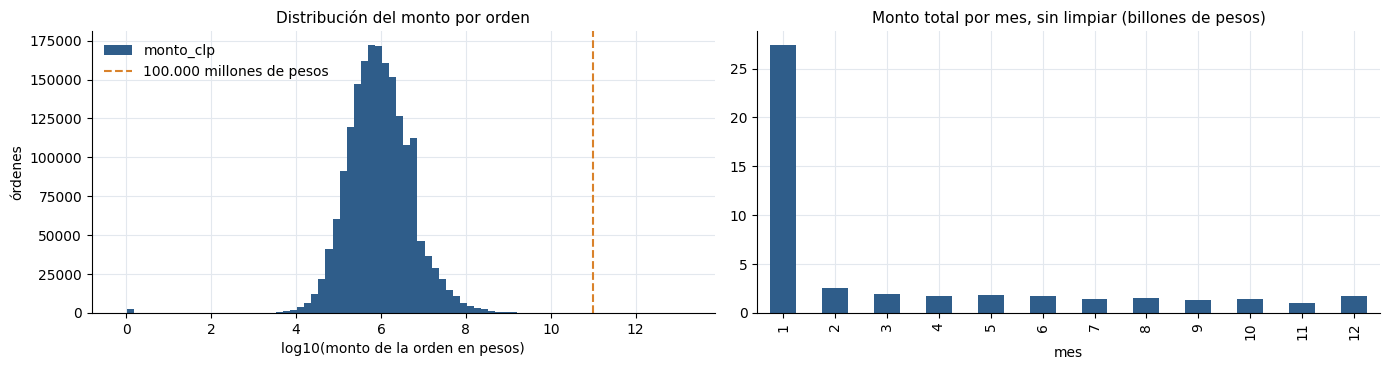

Las 15 órdenes más grandes:


,codigo,mes,estado,moneda,monto_original,monto_clp,organismo,nombre_proveedor
35800,2560-3-SE25,1,Aceptada,UTM,"233,500,000","15,744,671,499,995",I MUNICIPALIDAD DE LAS CONDES,SCP
6318,2667-1450-SE24,1,Cancelacion solicitada,UTM,"135,129,195","9,093,384,018,048",I MUNICIPALIDAD DE VITACURA,RAINDROP LTDA.
141182,85-429-SE24,2,Recepcion Conforme,CLP,"403,570,899,169","403,570,899,169",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,EDENRED CHILE SOCIEDAD ANONIMA
718593,2667-413-SE25,5,Aceptada,UTM,"5,708,406","391,870,668,818",I MUNICIPALIDAD DE VITACURA,Servicios Multitécnicos Sinergia Ltda.
416045,85-98-SE25,4,Aceptada,CLP,"314,396,802,821","314,396,802,821",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,MARCO ANTONIO
871442,1395481-9-SE25,6,Aceptada,CLF,"7,278,624","285,696,028,540",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,BCI SEGUROS VIDA S A
141181,85-428-SE24,2,Recepcion Conforme,CLP,"252,806,363,831","252,806,363,831",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,SODEXO SOLUCIONES DE MOTIVACION CHILE S.A.
106468,85-43-SE25,1,Enviada a proveedor,CLP,"244,511,699,289","244,511,699,289",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
269953,85-87-SE25,3,Aceptada,CLP,"235,457,183,114","235,457,183,114",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
862331,1186229-166-SE25,6,Recepcion Conforme,CLP,"229,220,958,511","229,220,958,511",SERVICIO DE REGISTRO CIVIL E IDENTIFICACION,IDEMIA IDENTITY & SECURITY CHILE



Órdenes en otra moneda con monto >= 100,000,000,000 pesos: 12
Suman 27.11 billones de 45.80 (59.2 %)

Para revisar: 20 órdenes en otra moneda entre 10.000 y 100.000 millones de pesos


,codigo,mes,estado,moneda,monto_original,monto_clp,organismo,nombre_proveedor
267776,85-67-SE25,3,Recepcion Conforme,USD,"37,216,141","36,736,796,724",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,NET NOW S.A.
1094810,4127-301-SE25,8,Recepcion Conforme,USD,"37,327,324","35,993,993,082",SUBSECRETARIA DE SALUD PUBLICA,HP INC CHILE COMERCIAL LIMITADA
910246,4707-257-SE25,7,Aceptada,CLF,"833,000","32,711,652,941",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1844,2667-1237-SE24,1,Aceptada,UTM,"490,623","32,656,334,094",I MUNICIPALIDAD DE VITACURA,STARCO S A
766167,4707-203-SE25,6,Aceptada,CLF,"833,000","32,651,127,031",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1124819,4707-305-SE25,8,Aceptada,CLF,"833,000","32,617,013,078",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
598050,4707-160-SE25,5,Aceptada,CLF,"833,000","32,571,464,898",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
445653,4707-121-SE25,4,Aceptada,CLF,"833,000","32,407,139,379",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1696405,2560-105-SE25,11,Aceptada,UTM,"406,089","28,240,225,715",I MUNICIPALIDAD DE LAS CONDES,BITACORA
1535463,2560-81-SE25,11,Aceptada,UTM,"403,187","27,926,760,064",I MUNICIPALIDAD DE LAS CONDES,BITACORA



Órdenes EN PESOS >= 100,000,000,000: 12


,codigo,mes,estado,moneda,monto_original,monto_clp,organismo,nombre_proveedor
141182,85-429-SE24,2,Recepcion Conforme,CLP,"403,570,899,169","403,570,899,169",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,EDENRED CHILE SOCIEDAD ANONIMA
416045,85-98-SE25,4,Aceptada,CLP,"314,396,802,821","314,396,802,821",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,MARCO ANTONIO
141181,85-428-SE24,2,Recepcion Conforme,CLP,"252,806,363,831","252,806,363,831",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,SODEXO SOLUCIONES DE MOTIVACION CHILE S.A.
106468,85-43-SE25,1,Enviada a proveedor,CLP,"244,511,699,289","244,511,699,289",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
269953,85-87-SE25,3,Aceptada,CLP,"235,457,183,114","235,457,183,114",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,Salud y Vida S.A.
862331,1186229-166-SE25,6,Recepcion Conforme,CLP,"229,220,958,511","229,220,958,511",SERVICIO DE REGISTRO CIVIL E IDENTIFICACION,IDEMIA IDENTITY & SECURITY CHILE
106455,85-37-SE25,1,Aceptada,CLP,"211,461,702,288","211,461,702,288",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,SERVICIOS ALIMENTICIOS HENDAYA SAC
106471,85-45-SE25,1,Aceptada,CLP,"207,355,546,556","207,355,546,556",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,sosersa
269957,85-97-SE25,3,Aceptada,CLP,"197,947,084,476","197,947,084,476",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,sosersa
269955,85-89-SE25,3,Aceptada,CLP,"193,037,661,793","193,037,661,793",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,COMERCIAL DE ALIMENTOS SOCIEDAD ANONIMA


In [ ]:
# Celda 6: revisión de los montos (distribución, conversión de monedas y órdenes extremas)

# Se carga la etapa de órdenes leídas (copia de trabajo; el archivo guardado no se modifica)
df = cargar_etapa("ordenes_leidas")
# Se define el umbral solo para esta exploración (el criterio final de limpieza está en la celda 1)
UMBRAL_EXPLORACION = 1e11

# Se resumen estadísticamente los montos por orden en pesos chilenos, con formato de miles
print("Monto por orden (CLP):")
print(df.monto_clp.describe(percentiles=[.5, .9, .99, .999]).apply(lambda v: f"{v:,.0f}").to_string())
print(f"\nÓrdenes con monto <= 0: {(df.monto_clp <= 0).sum()} | con monto <= 100 pesos: {(df.monto_clp <= 100).sum()}")

# Se estima el factor de conversión de cada moneda: pesos por unidad de la moneda original (mediana)
no_clp = df[(df.moneda.astype(str) != "CLP") & (df.monto_original > 0)]
factor = (no_clp.monto_clp / no_clp.monto_original).groupby(no_clp.moneda.astype(str)).median().round(0)
print("\nFactor de conversión implícito (pesos por unidad, mediana):")
print(factor.to_string())

# Se dibujan la distribución de los montos (escala logarítmica) y el monto total por mes sin limpiar
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
np.log10(df.monto_clp[df.monto_clp > 0]).plot.hist(bins=80, ax=ax[0], color=AZUL)
ax[0].axvline(np.log10(UMBRAL_EXPLORACION), color=NARANJA, ls="--", label="100.000 millones de pesos")
ax[0].set_xlabel("log10(monto de la orden en pesos)")
ax[0].set_ylabel("órdenes")
ax[0].set_title("Distribución del monto por orden")
ax[0].legend(frameon=False)
(df.groupby("mes").monto_clp.sum() / 1e12).plot.bar(ax=ax[1], color=AZUL)
ax[1].set_title("Monto total por mes, sin limpiar (billones de pesos)")
ax[1].set_xlabel("mes")
plt.tight_layout()
plt.show()

cols = ["codigo", "mes", "estado", "moneda", "monto_original", "monto_clp", "organismo", "nombre_proveedor"]
# Se muestran las 15 órdenes más grandes, sea cual sea su moneda
print("Las 15 órdenes más grandes:")
display(formatear(df.nlargest(15, "monto_clp")[cols], ["monto_original", "monto_clp"]))

# Se muestran las órdenes en OTRA moneda que superan el umbral de exploración
sosp = df[(df.moneda.astype(str) != "CLP") & (df.monto_clp >= UMBRAL_EXPLORACION)].sort_values("monto_clp", ascending=False)
print(f"\nÓrdenes en otra moneda con monto >= {UMBRAL_EXPLORACION:,.0f} pesos: {len(sosp)}")
print(f"Suman {sosp.monto_clp.sum()/1e12:.2f} billones de {df.monto_clp.sum()/1e12:.2f} ({100*sosp.monto_clp.sum()/df.monto_clp.sum():.1f} %)")

# Se muestran las órdenes en otra moneda entre 10.000 y 100.000 millones, para revisarlas a mano
cerca = df[(df.moneda.astype(str) != "CLP") & (df.monto_clp >= 1e10) & (df.monto_clp < UMBRAL_EXPLORACION)]
print(f"\nPara revisar: {len(cerca)} órdenes en otra moneda entre 10.000 y 100.000 millones de pesos")
display(formatear(cerca.sort_values("monto_clp", ascending=False)[cols], ["monto_original", "monto_clp"]).head(15))

# Se muestran las órdenes EN PESOS por sobre 100.000 millones, que no se marcan pero conviene conocer
clp_grandes = df[(df.moneda.astype(str) == "CLP") & (df.monto_clp >= UMBRAL_EXPLORACION)].sort_values("monto_clp", ascending=False)
print(f"\nÓrdenes EN PESOS >= {UMBRAL_EXPLORACION:,.0f}: {len(clp_grandes)}")
display(formatear(clp_grandes[cols], ["monto_original", "monto_clp"]).head(15))

**Qué se concluye:**
* Los factores de conversión son coherentes con 2025 (UF ≈ 39.200, UTM ≈ 68.800, USD ≈ 946, EUR ≈ 1.093): el error no está en la conversión, sino en el monto digitado.
* **12 órdenes en otra moneda sobre 100.000 millones suman el 59,2 % del monto total** (27,1 de 45,8 billones) y explican que enero se dispare en el gráfico: Las Condes (15,7 billones) y Vitacura (9,1 billones). Sin tratarlas, el ranking por monto mediría errores de digitación.
* Las órdenes **en pesos** sobre 100.000 millones (12) son casi todas de JUNAEB con empresas de alimentación, más Registro Civil y un servicio de salud; son montos plausibles y **no se excluyen**.
* Hay unas 3.000 órdenes de 100 pesos o menos (el pico en cero del histograma): son montos simbólicos.

## 7. Líneas de ítem de las órdenes sospechosas
**Celda 7:** lee las líneas de ítem de las órdenes en otra moneda que superan los 10.000 millones y compara el monto de la cabecera con la suma de sus líneas. También revisa las órdenes de monto simbólico. Tarda unos 4 minutos.

In [ ]:
# Celda 7: revisión de las líneas de ítem de las órdenes sospechosas y de los montos simbólicos

# Se carga la etapa de órdenes leídas
df = cargar_etapa("ordenes_leidas")

# Se juntan los códigos de las órdenes en otra moneda con monto de 10.000 millones de pesos o más
candidatas = df[(df.moneda.astype(str) != "CLP") & (df.monto_clp >= 1e10)]
codigos = set(candidatas.codigo)
print(f"Órdenes a revisar: {len(codigos)}")

# Se definen las columnas que se leen de cada CSV (leer solo estas acelera la lectura)
COLS_REV = ["Codigo", "TipoMonedaOC", "MontoTotalOC", "MontoTotalOC_PesosChilenos", "TotalNetoOC",
            "monedaItem", "cantidad", "precioNeto", "totalLineaNeto"]

# Se recorren los 12 meses y se guardan solo las filas (ítems) de esas órdenes
partes = []
for mes in range(1, 13):
    for bloque in pd.read_csv(RUTAS[mes], sep=";", encoding="cp1252", encoding_errors="replace",
                              dtype=str, keep_default_na=False, usecols=COLS_REV, chunksize=300_000):
        sel = bloque[bloque.Codigo.isin(codigos)]
        if len(sel):
            partes.append(sel)
    print(f"mes {mes:2d} revisado", end=" | ")
it = pd.concat(partes, ignore_index=True)

# Se convierten a número las columnas de montos, cambiando la coma decimal por punto
for c in ["MontoTotalOC", "MontoTotalOC_PesosChilenos", "TotalNetoOC", "cantidad", "precioNeto", "totalLineaNeto"]:
    it[c] = pd.to_numeric(it[c].str.replace(",", ".", regex=False), errors="coerce")

# Se arma un resumen por orden: moneda de la cabecera, moneda de los ítems y suma de las líneas
res = it.groupby("Codigo").agg(
    moneda_orden=("TipoMonedaOC", "first"),
    monedas_items=("monedaItem", lambda s: "/".join(sorted(set(s)))),
    n_items=("totalLineaNeto", "size"),
    monto_orden=("MontoTotalOC", "first"),
    neto_orden=("TotalNetoOC", "first"),
    suma_lineas=("totalLineaNeto", "sum"),
    monto_clp=("MontoTotalOC_PesosChilenos", "first"),
)
# Se calcula cuántas veces es mayor el monto de la cabecera que la suma de las líneas
res["orden/lineas"] = (res.monto_orden / res.suma_lineas).round(2)

print("\n\nCabecera vs suma de líneas (ordenadas por monto en pesos):")
fmt = {c: "{:,.0f}".format for c in ["monto_orden", "neto_orden", "suma_lineas", "monto_clp"]}
display(res.sort_values("monto_clp", ascending=False).style.format(fmt))

# ------------------------- MONTOS SIMBÓLICOS -------------------------

# Se revisan las órdenes de 100 pesos o menos: por moneda, tipo, estado y valor más frecuente
chicos = df[df.monto_clp <= 100]
print(f"\nÓrdenes con monto <= 100 pesos: {len(chicos):,}")
print("\nPor moneda:\n", chicos.moneda.astype(str).value_counts().to_string())
print("\nPor tipo:\n", chicos.tipo.astype(str).value_counts().to_string())
print("\nPor estado:\n", chicos.estado.astype(str).value_counts().to_string())
print("\nValores más frecuentes del monto:\n", chicos.monto_clp.round(2).value_counts().head(8).to_string())

Órdenes a revisar: 32
mes  1 revisado | mes  2 revisado | mes  3 revisado | mes  4 revisado | mes  5 revisado | mes  6 revisado | mes  7 revisado | mes  8 revisado | mes  9 revisado | mes 10 revisado | mes 11 revisado | mes 12 revisado | 

Cabecera vs suma de líneas (ordenadas por monto en pesos):


,moneda_orden,monedas_items,n_items,monto_orden,neto_orden,suma_lineas,monto_clp,orden/lineas
Codigo,,,,,,,,
2560-3-SE25,UTM,CLP,1,"233,500,000","196,218,487","196,218,487","15,744,671,499,995",1.190000
2667-1450-SE24,UTM,UTM,1,"135,129,195","113,553,945","113,553,945","9,093,384,018,048",1.190000
2667-413-SE25,UTM,CLP,1,"5,708,406","4,796,980","4,796,980","391,870,668,818",1.190000
1395481-9-SE25,CLF,CLF,1,"7,278,624","7,278,624","7,278,624","285,696,028,540",1.000000
2667-414-SE25,UTM,CLP,1,"3,267,645","2,745,920","2,745,920","224,317,280,230",1.190000
3833-1046-SE25,CLF,CLP,1,"5,242,181","4,405,194","4,405,194","208,200,768,967",1.190000
3833-784-SE25,CLF,CLP,1,"5,221,295","4,387,643","4,387,643","206,272,425,799",1.190000
3833-729-SE25,CLF,CLP,1,"5,207,732","4,376,245","4,376,245","205,630,657,140",1.190000
3833-520-SE25,CLF,CLP,1,"5,192,391","4,363,354","4,363,354","203,827,684,001",1.190000



Órdenes con monto <= 100 pesos: 2,994

Por moneda:
 moneda
CLP    2985
CLF       6
USD       3

Por tipo:
 tipo
SE    2724
TD     229
AG      37
CC       3
CT       1

Por estado:
 estado
Aceptada                  2788
Enviada a proveedor        150
Recepcion Conforme          48
En proceso                   5
Cancelacion solicitada       3

Valores más frecuentes del monto:
 monto_clp
1.19     2384
1.00      196
2.38       88
3.57       34
4.76       26
11.90      18
5.00       18
5.95       13


**Qué se concluye:**
* `monto_orden = suma de líneas × 1,19`: la cabecera incluye el IVA del 19 % y las líneas son netas (en las exentas la razón es 1,00).
* **Muchas veces el ítem viene en pesos aunque la cabecera diga UTM o UF** (por ejemplo Las Condes `2560-3-SE25`, Vitacura `2667-413-SE25` y las cinco órdenes de Río Bueno): el sistema multiplicó por 68.785 o 39.192 un monto que ya estaba en pesos. Esas órdenes se **corrigen** con el monto de la cabecera.
* Cuando el ítem también está en UTM, UF o USD (por ejemplo las seis órdenes de 833.000 CLF de San Nicolás, o los 37 millones de USD de HP y NET NOW) **no se puede saber** cuál es el monto real: se marcan como sospechosas.
* Las órdenes simbólicas valen exactamente 1,19, 2,38, 3,57…: es **1 peso neto por ítem más IVA**, un precio de relleno (casi todas `SE` en pesos, estado "Aceptada").

## 8. Moneda de los ítems en todas las órdenes en otra moneda
**Celda 8:** mide en cuántas de las 20.822 órdenes con cabecera en otra moneda los ítems vienen en pesos (el error de conversión) y cuánto monto se corrige. Guarda la etapa `monedas_items`. Tarda unos 5 minutos.

In [ ]:
# Celda 8: ¿en cuántas órdenes en otra moneda los ítems vienen en pesos? (posible error de conversión)

# Se carga la etapa de órdenes leídas
df = cargar_etapa("ordenes_leidas")

# Se toman los códigos de TODAS las órdenes cuya moneda de cabecera no es CLP
codigos_no_clp = set(df.loc[df.moneda.astype(str) != "CLP", "codigo"])
print(f"Órdenes con moneda de cabecera distinta de CLP: {len(codigos_no_clp):,}")

# Se recorren los 12 meses leyendo solo el código y la moneda del ítem (lectura rápida)
partes = []
for mes in range(1, 13):
    for bloque in pd.read_csv(RUTAS[mes], sep=";", encoding="cp1252", encoding_errors="replace",
                              dtype=str, keep_default_na=False, usecols=["Codigo", "monedaItem"],
                              chunksize=500_000):
        # Se conservan solo las filas de esas órdenes y se eliminan duplicados para ahorrar memoria
        sel = bloque[bloque.Codigo.isin(codigos_no_clp)].drop_duplicates()
        if len(sel):
            partes.append(sel)
    print(f"mes {mes:2d} revisado", end=" | ")

# Se resume, por orden, el conjunto de monedas de sus ítems (por ejemplo "CLP", "CLF" o "CLF/CLP")
it2 = pd.concat(partes, ignore_index=True).drop_duplicates()
monedas_items = it2.groupby("Codigo").monedaItem.agg(lambda s: "/".join(sorted(set(s)))).rename("monedas_items")

# Se guarda la etapa (código de la orden y moneda de sus ítems)
guardar_etapa(monedas_items.reset_index().rename(columns={"Codigo": "codigo"}), "monedas_items")

# Se une la moneda de los ítems a la tabla de órdenes en otra moneda
no_clp = df[df.moneda.astype(str) != "CLP"].merge(monedas_items, left_on="codigo", right_index=True, how="left")
no_clp["moneda"] = no_clp["moneda"].astype(str)

# Se cruzan la moneda de la cabecera y la de los ítems
print("\n\nMoneda de la cabecera (filas) vs moneda de los ítems (columnas), en número de órdenes:")
display(pd.crosstab(no_clp.moneda, no_clp.monedas_items.fillna("(sin dato)")))

# Se identifican las órdenes con el posible error: cabecera en otra moneda pero ítems solo en pesos
err = no_clp[no_clp.monedas_items == "CLP"]
print(f"\nÓrdenes con cabecera en otra moneda e ítems solo en CLP: {len(err):,} de {len(no_clp):,}")

# Se compara el monto actual (convertido) con el monto corregido (el de la cabecera, ya en pesos)
imp = err.groupby("moneda").agg(
    ordenes=("codigo", "size"),
    monto_actual_millones=("monto_clp", lambda s: round(s.sum() / 1e6)),
    monto_corregido_millones=("monto_original", lambda s: round(s.sum() / 1e6)),
)
print("\nEfecto de la corrección, por moneda de cabecera (millones de pesos):")
display(imp.style.format("{:,.0f}"))

# Se calcula el monto en pesos corregido para todas las órdenes en otra moneda
no_clp["monto_clp_corr"] = np.where(no_clp.monedas_items == "CLP", no_clp.monto_original, no_clp.monto_clp)

# Se listan las órdenes que seguirían con 10.000 millones o más después de corregir
restantes = no_clp[no_clp.monto_clp_corr >= 1e10].sort_values("monto_clp_corr", ascending=False)
print(f"\nÓrdenes que siguen >= 10.000 millones de pesos después de corregir: {len(restantes)}")
print(f"Suman {restantes.monto_clp_corr.sum()/1e12:,.2f} billones de pesos")
cols = ["codigo", "moneda", "monedas_items", "monto_original", "monto_clp_corr", "organismo", "nombre_proveedor"]
display(restantes[cols].head(30).style.format({"monto_original": "{:,.0f}", "monto_clp_corr": "{:,.0f}"}))

Órdenes con moneda de cabecera distinta de CLP: 20,822
mes  1 revisado | mes  2 revisado | mes  3 revisado | mes  4 revisado | mes  5 revisado | mes  6 revisado | mes  7 revisado | mes  8 revisado | mes  9 revisado | mes 10 revisado | mes 11 revisado | mes 12 revisado | 

Moneda de la cabecera (filas) vs moneda de los ítems (columnas), en número de órdenes:


monedas_items,CLF,CLP,EUR,USD,UTM
moneda,,,,,
CLF,11247,34,0,5,2
EUR,0,0,52,0,0
USD,0,8,0,8797,0
UTM,7,3,0,0,667



Órdenes con cabecera en otra moneda e ítems solo en CLP: 45 de 20,822

Efecto de la corrección, por moneda de cabecera (millones de pesos):


,ordenes,monto_actual_millones,monto_corregido_millones
moneda,,,
CLF,34,"1,251,375",32
USD,8,295,0
UTM,3,"16,360,859",242



Órdenes que siguen >= 10.000 millones de pesos después de corregir: 21
Suman 9.99 billones de pesos


,codigo,moneda,monedas_items,monto_original,monto_clp_corr,organismo,nombre_proveedor
6318,2667-1450-SE24,UTM,UTM,"135,129,195","9,093,384,018,048",I MUNICIPALIDAD DE VITACURA,RAINDROP LTDA.
871442,1395481-9-SE25,CLF,CLF,"7,278,624","285,696,028,540",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,BCI SEGUROS VIDA S A
1855581,2699-120-SE25,CLF,CLF,"4,267,521","169,523,516,207",I MUNICIPALIDAD DE LA REINA,Productora de Seguros Raimundo García de la Huerta
267776,85-67-SE25,USD,USD,"37,216,141","36,736,796,724",JUNTA NACIONAL DE AUXILIO ESCOLAR Y BECA,NET NOW S.A.
1094810,4127-301-SE25,USD,USD,"37,327,324","35,993,993,082",SUBSECRETARIA DE SALUD PUBLICA,HP INC CHILE COMERCIAL LIMITADA
910246,4707-257-SE25,CLF,CLF,"833,000","32,711,652,941",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1844,2667-1237-SE24,UTM,UTM,"490,623","32,656,334,094",I MUNICIPALIDAD DE VITACURA,STARCO S A
766167,4707-203-SE25,CLF,CLF,"833,000","32,651,127,031",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
1124819,4707-305-SE25,CLF,CLF,"833,000","32,617,013,078",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA
598050,4707-160-SE25,CLF,CLF,"833,000","32,571,464,898",I MUNICIPALIDAD DE SAN NICOLAS,VENDING STORE LIMITADA


**Qué se concluye:**
* El error de conversión es **raro**: solo 45 de las 20.822 órdenes en otra moneda tienen la cabecera en UTM, UF o USD con los ítems en pesos (la gran mayoría es consistente: 11.247 en CLF con ítems en CLF y 8.797 en USD con ítems en USD). No hay órdenes pequeñas infladas por debajo del umbral de forma sistemática.
* Pero esas 45 pesaban mucho: figuraban con **17,6 billones** y corregidas valen unos **274 millones de pesos**.
* Después de corregir quedan **21 órdenes sobre 10.000 millones** (9,99 billones, de los cuales 9,09 son una sola orden cancelada de Vitacura). Son casos ambiguos y se marcan como sospechosas, no se borran.

## 9. Reglas de limpieza
**Celda 9:** aplica todas las reglas sobre **una copia** de las órdenes leídas, mide cuánto afecta cada una y guarda la etapa `ordenes_limpias`. Nada se borra: las órdenes se **marcan**.

| # | Regla | Por qué |
|---|---|---|
| 1 | Una fila por orden (`Codigo`) | El monto de la orden se repite en cada ítem |
| 2 | `proveedor_id` = código del proveedor; si falta, `RUT_` + RUT; si no hay ninguno, la orden no se usa | `CodigoProveedor` casi nunca falta; `RutSucursal` sí en algunos casos |
| 3 | Nombre de proveedor y organismo = el más frecuente para su código | El mismo código aparece con nombres escritos distinto |
| 4 | **Corregida:** cabecera en otra moneda con ítems solo en pesos → se usa `MontoTotalOC` | La conversión se aplicó a un monto que ya estaba en pesos |
| 5 | **Sospechosa:** otra moneda y monto corregido ≥ `UMBRAL_MONTO_SOSPECHOSO` (y no está en `LISTA_BLANCA`) | Montos ambiguos con el ítem en moneda extranjera |
| 6 | **Simbólica:** monto ≤ 100 pesos | Precio de relleno (1 peso por ítem) |
| 7 | **Inválida:** monto ≤ 0 o vacío | Sin sentido económico |
| 8 | **Estado excluido:** `Cancelacion solicitada` | No representan una compra concretada |
| 9 | **Persona natural:** RUT numérico menor a 50 millones | Aproximación por rango de RUT |

Las órdenes sospechosas, simbólicas e inválidas **no suman monto**, pero siguen contando como órdenes y como conexiones del grafo.

In [ ]:
# Celda 9: aplicación de las reglas de limpieza sobre una copia de las órdenes leídas

# Se carga una copia de trabajo de las órdenes leídas (el archivo de la etapa 5 no se modifica)
df = cargar_etapa("ordenes_leidas")
# Se carga la moneda de los ítems de las órdenes en otra moneda (etapa de la celda 8)
monedas_items = cargar_etapa("monedas_items").set_index("codigo")["monedas_items"]

# ------------------------- IDENTIDAD DE PROVEEDOR Y ORGANISMO -------------------------

# Se obtienen como texto el código y el RUT del proveedor (las columnas están como "category")
cod_prov = df.cod_proveedor.astype(str)
rut = df.rut_proveedor.astype(str)
# Se define el identificador del proveedor: su código; si falta, "RUT_" + RUT; si no hay ninguno, queda vacío
df["proveedor_id"] = np.where(cod_prov != "", cod_prov, np.where(rut != "", "RUT_" + rut, ""))

# Se define una función que entrega, para cada clave, el nombre que más se repite (los nombres vienen escritos distinto)
def mas_frecuente(clave, valor):
    t = pd.DataFrame({"k": clave.astype(str), "v": valor.astype(str)})
    t = t[(t.k != "") & (t.v != "")]
    t = t.groupby(["k", "v"]).size().reset_index(name="n")
    return t.sort_values("n", ascending=False).drop_duplicates("k").set_index("k")["v"]

# Se reemplazan los nombres por el más frecuente; si no hay, se deja el original
nombre_prov = mas_frecuente(df.proveedor_id, df.nombre_proveedor)
nombre_org = mas_frecuente(df.cod_organismo, df.organismo)
df["nombre_proveedor"] = df.proveedor_id.map(nombre_prov).fillna(df.nombre_proveedor.astype(str))
df["organismo"] = df.cod_organismo.astype(str).map(nombre_org).fillna(df.organismo.astype(str))
# Se rotulan "(sin sector)" las órdenes sin sector
df["sector"] = df.sector.astype(str).replace("", "(sin sector)")

# ------------------------- PERSONA NATURAL -------------------------

# Se extrae la parte numérica del RUT (sin puntos ni dígito verificador)
num_rut = pd.to_numeric(rut.str.extract(r"^([\d\.]+)-[\dkK]$")[0].str.replace(".", "", regex=False), errors="coerce")
# Se marca "1" si es persona natural, "0" si es jurídica y vacío si el RUT no se puede interpretar
df["es_persona_natural"] = np.where(num_rut.isna(), "", np.where(num_rut < RUT_MAX_PERSONA_NATURAL, "1", "0"))

# ------------------------- MONTOS -------------------------

# Se obtiene la moneda de los ítems de cada orden (vacía para las órdenes en CLP)
moneda_items = df.codigo.map(monedas_items)
# Se marcan para corregir las órdenes con cabecera en otra moneda e ítems solo en pesos
corregir = (df.moneda.astype(str) != "CLP") & (moneda_items == "CLP")
# Se calcula el monto corregido: el de la cabecera (ya en pesos) para esas órdenes, el convertido para el resto
df["monto_clp_corr"] = np.where(corregir, df.monto_original, df.monto_clp)
df["monto_corregido"] = corregir.astype(int)

# Se asignan las marcas de monto, de menor a mayor prioridad (la última que se aplica prevalece)
df["flag_monto"] = ""
df.loc[(df.monto_clp_corr > 0) & (df.monto_clp_corr <= MONTO_SIMBOLICO_MAX), "flag_monto"] = "simbolico"
sospechosa = ((df.moneda.astype(str) != "CLP") & (df.monto_clp_corr >= UMBRAL_MONTO_SOSPECHOSO)
              & (~df.codigo.isin(LISTA_BLANCA)))
df.loc[sospechosa, "flag_monto"] = "sospechoso"
df.loc[df.monto_clp_corr.isna() | (df.monto_clp_corr <= 0), "flag_monto"] = "invalido"
# Se deja el monto limpio solo en las órdenes sin marca (en las demás queda vacío)
df["monto_clp_limpio"] = df.monto_clp_corr.where(df.flag_monto == "")

# ------------------------- QUÉ ÓRDENES SE USAN -------------------------

# Se excluyen las órdenes de estado cancelado y las que no tienen proveedor
df["usar"] = ((~df.estado.astype(str).isin(ESTADOS_EXCLUIDOS)) & (df.proveedor_id != "")).astype(int)

# Se convierten a "category" las columnas de texto repetitivo para ahorrar memoria y se guarda la etapa
for c in ["nombre_proveedor", "organismo", "sector", "proveedor_id"]:
    df[c] = df[c].astype("category")
guardar_etapa(df, "ordenes_limpias")

# ------------------------- EFECTO DE CADA REGLA -------------------------

total = df.monto_clp.sum()
filas = [
    ("monto corregido (ítems en pesos)", df.monto_corregido == 1),
    ("monto sospechoso", df.flag_monto == "sospechoso"),
    ("monto simbólico (<= 100 pesos)", df.flag_monto == "simbolico"),
    ("monto inválido (<= 0)", df.flag_monto == "invalido"),
    ("estado excluido (cancelación solicitada)", df.estado.astype(str).isin(ESTADOS_EXCLUIDOS)),
    ("sin proveedor", df.proveedor_id == ""),
]
# Se arma la tabla: órdenes afectadas y monto que tenían según el archivo original (las reglas se solapan)
efecto = pd.DataFrame([(n, int(m.sum()), df.loc[m, "monto_clp"].sum()) for n, m in filas],
                      columns=["regla", "ordenes", "monto_original_pesos"])
efecto["% de las órdenes"] = (100 * efecto.ordenes / len(df)).round(3)
efecto["% del monto sin limpiar"] = (100 * efecto.monto_original_pesos / total).round(1)
efecto["monto_original_pesos"] = efecto.monto_original_pesos.map("{:,.0f}".format)

usadas = df[df.usar == 1]
print(f"Órdenes: {len(df):,} | se usan en los rankings: {len(usadas):,} "
      f"| proveedores: {usadas.proveedor_id.nunique():,} | organismos: {usadas.cod_organismo.nunique():,}")
print(f"Monto total sin limpiar: {total/1e12:,.2f} billones | monto limpio de las órdenes usadas: {usadas.monto_clp_limpio.sum()/1e12:,.2f} billones")
print("(los porcentajes no se suman: las reglas se solapan, por ejemplo la orden cancelada de Vitacura también es sospechosa)")
display(efecto)

# Se compara con el criterio alternativo de usar el estado del proveedor
print("Órdenes con EstadoProveedor = 'Cancelacion solicitada':", int((df.estado_proveedor.astype(str) == "Cancelacion solicitada").sum()),
      "| con Estado = 'Cancelacion solicitada':", int((df.estado.astype(str) == "Cancelacion solicitada").sum()))

# Se muestra qué proveedores concentran las órdenes simbólicas (afectan el ranking por número de órdenes)
simb = df[df.flag_monto == "simbolico"]
print("\nProveedores con más órdenes simbólicas:")
display(simb.groupby(["proveedor_id", "nombre_proveedor"], observed=True).size()
        .sort_values(ascending=False).head(10).to_frame("ordenes_simbolicas"))

# ------------------------- COMPROBACIÓN CON LAS CIFRAS YA VALIDADAS -------------------------

obtenido = {"ordenes": len(df), "ordenes_usadas": len(usadas), "proveedores": usadas.proveedor_id.nunique(),
            "organismos": usadas.cod_organismo.nunique(), "corregidas": int(df.monto_corregido.sum()),
            "sospechosas": int((df.flag_monto == "sospechoso").sum()), "simbolicas": int((df.flag_monto == "simbolico").sum()),
            "invalidas": int((df.flag_monto == "invalido").sum())}
esperado = {"ordenes": 1856038, "ordenes_usadas": 1853390, "proveedores": 75600, "organismos": 1165,
            "corregidas": 45, "sospechosas": 21, "simbolicas": 3004, "invalidas": 1}
comp = pd.DataFrame({"obtenido": obtenido, "esperado": esperado})
comp["estado"] = np.where(comp.obtenido == comp.esperado, "OK", "REVISAR")
print("\nComprobación con las cifras validadas (se esperan con los parámetros por defecto):")
display(comp)

Órdenes: 1,856,038 | se usan en los rankings: 1,853,390 | proveedores: 75,600 | organismos: 1,165
Monto total sin limpiar: 45.80 billones | monto limpio de las órdenes usadas: 18.18 billones
(los porcentajes no se suman: las reglas se solapan, por ejemplo la orden cancelada de Vitacura también es sospechosa)


,regla,ordenes,monto_original_pesos,% de las órdenes,% del monto sin limpiar
0,monto corregido (ítems en pesos),45,"17,612,529,200,476",0.002,38.5
1,monto sospechoso,21,"9,991,561,403,500",0.001,21.8
2,monto simbólico (<= 100 pesos),3004,"12,902,300",0.162,0.0
3,monto inválido (<= 0),1,-1,0.000,-0.0
4,estado excluido (cancelación solicitada),2637,"9,116,127,444,383",0.142,19.9
5,sin proveedor,11,"21,066,689",0.001,0.0


Órdenes con EstadoProveedor = 'Cancelacion solicitada': 4409 | con Estado = 'Cancelacion solicitada': 2637

Proveedores con más órdenes simbólicas:


,,ordenes_simbolicas
proveedor_id,nombre_proveedor,
24141,MUNNICH PHARMA MEDICAL SPA,44
269948,ETHON PHARMACEUTICALS COMERCIALIZADORA IMP EXP Y DIST SPA,34
47740,B BRAUN MEDICAL SPA,24
39998,DROGUERIA HOFMANN SAC,24
26782,LABORATORIO SANDERSON S.A.,23
103860,LABORATORIO CHILE S A,23
28150,NOVOFARMA SERVICE S A,22
1187276,SOCIEDAD COMERCIALIZADORA DE INSUMOS MEDICOS CLP S.A.,19
47654,COMERCIAL MEDTRONIC CHILE LTDA,19



Comprobación con las cifras validadas (se esperan con los parámetros por defecto):


,obtenido,esperado,estado
ordenes,1856038,1856038,OK
ordenes_usadas,1853390,1853390,OK
proveedores,75600,75600,OK
organismos,1165,1165,OK
corregidas,45,45,OK
sospechosas,21,21,OK
simbolicas,3004,3004,OK
invalidas,1,1,OK


**Qué se concluye:**
* Con las reglas aplicadas, quedan **1.853.390 órdenes** que se usan en los rankings, de **75.600 proveedores** y **1.165 organismos**. El monto limpio es de unos **18,18 billones** (sobre 45,80 sin limpiar).
* La corrección y la marca de sospechosas son lo que más cambia el monto; las simbólicas casi no lo cambian (suman unos 13 millones de pesos) pero sí cuentan como órdenes.
* Las simbólicas están repartidas entre laboratorios y distribuidoras médicas (19 a 44 por proveedor), muy lejos de los líderes del ranking de órdenes, así que se dejan contando como órdenes.
* `Estado` marca 2.637 cancelaciones y `EstadoProveedor` 4.409. Se mantiene `Estado` y la columna `estado_proveedor` queda en el archivo para probar el otro criterio.

## 10. Monto por mes, antes y después de limpiar
**Celda 10:** compara el monto total por mes sin limpiar y limpio, para ver el efecto de la limpieza.

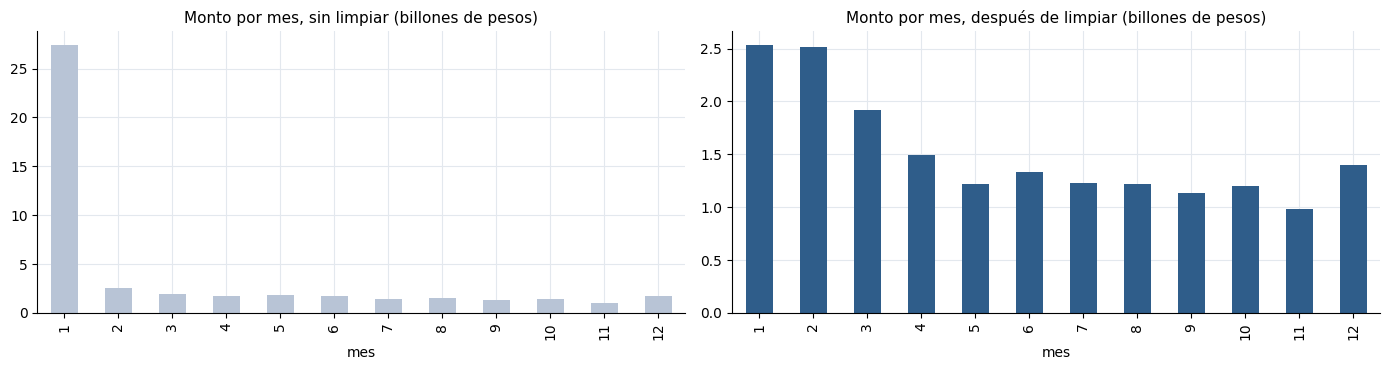

,sin_limpiar,limpio
mes,,
1,27.43,2.54
2,2.52,2.52
3,1.96,1.92
4,1.72,1.49
5,1.88,1.22
6,1.69,1.33
7,1.47,1.23
8,1.51,1.22
9,1.37,1.14


In [ ]:
# Celda 10: monto total por mes, antes y después de la limpieza

# Se carga la etapa de órdenes limpias
df = cargar_etapa("ordenes_limpias")
# Se toman las órdenes que se usan en los rankings (sin canceladas ni sin proveedor)
usadas = df[df.usar == 1]

# Se calcula el monto total por mes sin limpiar (el que viene en el archivo original) y limpio, en billones de pesos
antes = df.groupby("mes").monto_clp.sum() / 1e12
despues = usadas.groupby("mes").monto_clp_limpio.sum() / 1e12

# Se dibujan los dos gráficos lado a lado, cada uno con su propia escala
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
antes.plot.bar(ax=ax[0], color=GRIS)
ax[0].set_title("Monto por mes, sin limpiar (billones de pesos)")
ax[0].set_xlabel("mes")
despues.plot.bar(ax=ax[1], color=AZUL)
ax[1].set_title("Monto por mes, después de limpiar (billones de pesos)")
ax[1].set_xlabel("mes")
plt.tight_layout()
plt.show()

# Se muestra la tabla con los valores de cada mes
pd.DataFrame({"sin_limpiar": antes.round(2), "limpio": despues.round(2)})

## 11. Exportación de los archivos para el clúster
**Celda 11:** escribe en `salida_v2`, en UTF-8, separados por tabulador y sin comillas:

| archivo | contenido |
|---|---|
| `ordenes_limpias.tsv` | una fila por orden (30 columnas, con cabecera). **Insumo de Pig.** |
| `ordenes_muestra.tsv` | 10.000 órdenes al azar para desarrollar scripts |
| `aristas.tsv` | grafo organismo → proveedor, dos columnas (`origen`, `destino`), como en el Lab 8. **Insumo de Giraph.** |
| `aristas_bidireccional.tsv` | las mismas aristas en ambos sentidos |
| `aristas_ponderadas.tsv` | origen, destino, número de órdenes y monto limpio |
| `aristas_muestra.tsv` | aristas armadas solo con la muestra |
| `nodos.tsv` | nombre de cada organismo y proveedor, para poner nombre a los resultados |
| `proveedor_rubro.tsv` | monto neto por proveedor y rubro |
| `resumen_calidad.json` | cifras clave |

In [ ]:
# Celda 11: exportación de los archivos para el clúster

# Se cargan las etapas necesarias
df = cargar_etapa("ordenes_limpias")
rubros = cargar_etapa("proveedor_rubro")
resumen = pd.read_csv(ruta_etapa("resumen_lectura.csv"), index_col="mes")

# Se define el orden de las columnas del archivo principal (30 columnas, una fila por orden)
COLS_SALIDA = ["codigo", "mes", "fecha_envio", "fecha_creacion", "fecha_aceptacion", "estado", "estado_proveedor",
               "tipo", "procedencia", "cod_licitacion", "cod_convenio_marco", "moneda", "monto_original",
               "monto_clp", "monto_clp_corr", "monto_corregido", "monto_clp_limpio", "flag_monto", "n_items",
               "cod_organismo", "organismo", "sector", "region_comprador", "proveedor_id", "rut_proveedor",
               "nombre_proveedor", "es_persona_natural", "region_proveedor", "actividad_proveedor", "usar"]
# Se define el formato común: tabulador, sin comillas, montos con 2 decimales y vacío para nulos
FORMATO = dict(sep="\t", index=False, float_format="%.2f", na_rep="", quoting=csv.QUOTE_NONE)

# ------------------------- ARCHIVO PRINCIPAL Y MUESTRA -------------------------

df[COLS_SALIDA].to_csv(ruta("ordenes_limpias.tsv"), **FORMATO)
muestra_ord = df[COLS_SALIDA].sample(MUESTRA_N, random_state=SEED).sort_values("codigo")
muestra_ord.to_csv(ruta("ordenes_muestra.tsv"), **FORMATO)

# Se comprueba que el archivo principal tenga una línea por orden más la cabecera (no hay saltos de línea internos)
with open(ruta("ordenes_limpias.tsv"), encoding="utf-8") as f:
    lineas = sum(1 for _ in f)
assert lineas == len(df) + 1, f"el archivo tiene {lineas:,} líneas y se esperaban {len(df)+1:,}"
print(f"ordenes_limpias.tsv verificado: {lineas-1:,} órdenes + cabecera")

# ------------------------- GRAFO ORGANISMO -> PROVEEDOR -------------------------

# Se define la función que arma las aristas únicas organismo -> proveedor con cantidad de órdenes y monto limpio
def construir_aristas(d):
    # Se usan solo las órdenes que se consideran válidas para los rankings
    u = d[d.usar == 1]
    a = (u.assign(org=u.cod_organismo.astype(str), prov=u.proveedor_id.astype(str))
          .groupby(["org", "prov"], as_index=False)
          .agg(n_ordenes=("codigo", "size"), monto_clp=("monto_clp_limpio", "sum")))
    # Se agregan prefijos para que un código de organismo nunca se confunda con uno de proveedor
    a["origen"] = "ORG_" + a.org
    a["destino"] = "PROV_" + a.prov
    return a[["origen", "destino", "n_ordenes", "monto_clp"]]

ar = construir_aristas(df)
ar_muestra = construir_aristas(df[df.codigo.isin(muestra_ord.codigo)])

# Se escribe la versión dirigida (solo origen y destino, formato del Lab 8) y la de muestra
ar[["origen", "destino"]].to_csv(ruta("aristas.tsv"), sep="\t", index=False, header=False)
ar_muestra[["origen", "destino"]].to_csv(ruta("aristas_muestra.tsv"), sep="\t", index=False, header=False)
# Se escribe la versión bidireccional: cada arista en ambos sentidos
inversa = ar[["destino", "origen"]].set_axis(["origen", "destino"], axis=1)
pd.concat([ar[["origen", "destino"]], inversa]).to_csv(ruta("aristas_bidireccional.tsv"), sep="\t", index=False, header=False)
# Se escribe la versión ponderada: origen, destino, número de órdenes y monto limpio
ar.round(2).to_csv(ruta("aristas_ponderadas.tsv"), sep="\t", index=False, header=False)

# ------------------------- NOMBRES DE LOS NODOS -------------------------

# Se arma una tabla con una fila por nodo (organismo o proveedor) para poner nombre a los resultados
u = df[df.usar == 1]
prov_tab = (u.assign(p=u.proveedor_id.astype(str)).drop_duplicates("p")
              .assign(nodo=lambda t: "PROV_" + t.p, tipo_nodo="proveedor",
                      nombre=lambda t: t.nombre_proveedor.astype(str), dato=lambda t: t.es_persona_natural)
              [["nodo", "tipo_nodo", "nombre", "dato"]])
org_tab = (u.assign(o=u.cod_organismo.astype(str)).drop_duplicates("o")
             .assign(nodo=lambda t: "ORG_" + t.o, tipo_nodo="organismo",
                     nombre=lambda t: t.organismo.astype(str), dato=lambda t: t.sector.astype(str))
             [["nodo", "tipo_nodo", "nombre", "dato"]])
nodos = pd.concat([org_tab, prov_tab])
nodos.to_csv(ruta("nodos.tsv"), sep="\t", index=False, quoting=csv.QUOTE_NONE)

# ------------------------- PROVEEDOR x RUBRO -------------------------

rubros.round(2).to_csv(ruta("proveedor_rubro.tsv"), sep="\t", index=False, quoting=csv.QUOTE_NONE)

# ------------------------- RESUMEN -------------------------

resumen_json = {
    "lineas": int(resumen.lineas.sum()), "ordenes": int(len(df)), "ordenes_usadas": int(len(u)),
    "proveedores": int(u.proveedor_id.nunique()), "organismos": int(u.cod_organismo.nunique()),
    "aristas": int(len(ar)), "ordenes_corregidas": int(df.monto_corregido.sum()),
    "ordenes_sospechosas": int((df.flag_monto == "sospechoso").sum()),
    "ordenes_simbolicas": int((df.flag_monto == "simbolico").sum()),
    "ordenes_invalidas": int((df.flag_monto == "invalido").sum()),
    "monto_sin_limpiar_clp": float(df.monto_clp.sum()), "monto_limpio_clp": float(u.monto_clp_limpio.sum()),
    "umbral_monto_sospechoso": UMBRAL_MONTO_SOSPECHOSO, "estados_excluidos": sorted(ESTADOS_EXCLUIDOS),
}
with open(ruta("resumen_calidad.json"), "w") as f:
    json.dump(resumen_json, f, indent=1, ensure_ascii=False)

print(pd.Series(resumen_json).to_string(), "\n")
for nombre in ["ordenes_limpias.tsv", "ordenes_muestra.tsv", "aristas.tsv", "aristas_bidireccional.tsv",
               "aristas_ponderadas.tsv", "aristas_muestra.tsv", "nodos.tsv", "proveedor_rubro.tsv", "resumen_calidad.json"]:
    print(f"{nombre:28s} {os.path.getsize(ruta(nombre))/1e6:8.1f} MB")

ordenes_limpias.tsv verificado: 1,856,038 órdenes + cabecera
lineas                                      5141167
ordenes                                     1856038
ordenes_usadas                              1853390
proveedores                                   75600
organismos                                     1165
aristas                                      476703
ordenes_corregidas                               45
ordenes_sospechosas                              21
ordenes_simbolicas                             3004
ordenes_invalidas                                 1
monto_sin_limpiar_clp         45797805527867.320312
monto_limpio_clp              18183640438447.585938
umbral_monto_sospechoso               10000000000.0
estados_excluidos          [Cancelacion solicitada] 

ordenes_limpias.tsv             774.2 MB
ordenes_muestra.tsv               4.2 MB
aristas.tsv                      10.9 MB
aristas_bidireccional.tsv        21.8 MB
aristas_ponderadas.tsv           16.7 MB
aris

## 12. Compresión del archivo principal
**Celda 12:** verifica los archivos exportados con sus conteos de líneas y comprime `ordenes_limpias.tsv` con bz2 (Pig y Hadoop lo leen directamente y puede repartirse entre máquinas). Tarda unos 3 minutos.

In [ ]:
# Celda 12: verificación de los archivos exportados y compresión del archivo principal con bz2

# Se define la lista de archivos que deben existir
ESPERADOS = ["ordenes_limpias.tsv", "ordenes_muestra.tsv", "aristas.tsv", "aristas_bidireccional.tsv",
             "aristas_ponderadas.tsv", "aristas_muestra.tsv", "nodos.tsv", "proveedor_rubro.tsv", "resumen_calidad.json"]
# Se exige que existan (si falta alguno, indica qué ejecutar)
exigir(*ESPERADOS)

# Se define una función que cuenta las líneas de un archivo
def contar(nombre):
    with open(ruta(nombre), "rb") as f:
        return sum(1 for _ in f)

# Se comparan los conteos de líneas con lo esperado, según el resumen guardado
with open(ruta("resumen_calidad.json")) as f:
    rc = json.load(f)
print("ordenes_limpias.tsv:", f"{contar('ordenes_limpias.tsv'):,}", f"(esperado {rc['ordenes'] + 1:,}: órdenes + cabecera)")
print("aristas.tsv        :", f"{contar('aristas.tsv'):,}", f"(esperado {rc['aristas']:,})")
print("nodos.tsv          :", f"{contar('nodos.tsv'):,}", f"(esperado {rc['proveedores'] + rc['organismos'] + 1:,}: nodos + cabecera)")
print("ordenes_muestra.tsv:", f"{contar('ordenes_muestra.tsv'):,}", f"(esperado {MUESTRA_N + 1:,}: muestra + cabecera)")

# Se crea una carpeta temporal local (comprimir en local es más rápido y seguro que hacerlo sobre Drive)
tmp = tempfile.mkdtemp()
shutil.copy(ruta("ordenes_limpias.tsv"), tmp + "/ordenes_limpias.tsv")
# Se comprime con bzip2 (nivel 9) conservando el original (-k)
subprocess.run(["bzip2", "-9", "-k", "-f", tmp + "/ordenes_limpias.tsv"], check=True)
# Se verifica la integridad del archivo comprimido (si falla, lanza un error)
subprocess.run(["bzip2", "-t", tmp + "/ordenes_limpias.tsv.bz2"], check=True)
# Se copia el archivo comprimido a la carpeta de salida
shutil.copy(tmp + "/ordenes_limpias.tsv.bz2", ruta("ordenes_limpias.tsv.bz2"))

antes = os.path.getsize(ruta("ordenes_limpias.tsv")) / 1e6
despues = os.path.getsize(ruta("ordenes_limpias.tsv.bz2")) / 1e6
print(f"\nOriginal: {antes:,.0f} MB | comprimido: {despues:,.0f} MB | verificación OK")
shutil.rmtree(tmp)

ordenes_limpias.tsv: 1,856,039 (esperado 1,856,039: órdenes + cabecera)
aristas.tsv        : 476,703 (esperado 476,703)
nodos.tsv          : 76,766 (esperado 76,766: nodos + cabecera)
ordenes_muestra.tsv: 10,001 (esperado 10,001: muestra + cabecera)

Original: 774 MB | comprimido: 85 MB | verificación OK


## 13. Rankings de control con pandas
**Celda 13:** calcula los mismos rankings que se harán en Pig (monto total, órdenes distintas, organismos distintos), la concentración del gasto y la evolución mensual, solo con órdenes usadas y monto limpio. Sirven para **comparar con la salida de Pig**. Guarda `control_metricas_proveedor.csv` y `control_evolucion_mensual.csv`.

75,600 proveedores con órdenes usadas

TOP 10 por monto total (millones de pesos)


,nombre,monto_MM,n_ordenes,n_organismos,es_persona_natural
proveedor_id,,,,,
27693,EDENRED CHILE SOCIEDAD ANONIMA,507605.0,5284,463,0
97685,Salud y Vida S.A.,480842.0,3,1,0
83487,sosersa,456447.0,6,1,0
76304,DAVITA CHILE S.A.,330522.0,254,25,0
22259,COMERCIAL DE ALIMENTOS SOCIEDAD ANONIMA,324992.0,30,6,0
1500814,MARCO ANTONIO,324528.0,24,4,0
27211,SODEXO SOLUCIONES DE MOTIVACION CHILE S.A.,273639.0,648,52,0
1408541,IDEMIA IDENTITY & SECURITY CHILE,231218.0,7,3,0
27324,SERVICIOS ALIMENTICIOS HENDAYA SAC,211809.0,3,1,0


TOP 10 por número de órdenes


,nombre,monto_MM,n_ordenes,n_organismos,es_persona_natural
proveedor_id,,,,,
25638,LATAM AIRLINES GROUP S.A.,17317.0,49937,543,0
71217,SKY AIRLINE S A,4891.0,16965,460,0
47654,COMERCIAL MEDTRONIC CHILE LTDA,65091.0,14571,129,0
26963,JOHNSON Y JOHNSON DE CHILE S A,118554.0,12426,127,0
24141,MUNNICH PHARMA MEDICAL SPA,31316.0,11190,436,0
26741,COPEC S.A.,116146.0,11018,830,0
47740,B BRAUN MEDICAL SPA,41604.0,10980,201,0
27247,GASCO GLP S A,38035.0,8777,699,0
44105,Fresenius Kabi Chile Ltda.,42515.0,8326,129,0


TOP 10 por organismos distintos


,nombre,monto_MM,n_ordenes,n_organismos,es_persona_natural
proveedor_id,,,,,
26741,COPEC S.A.,116146.0,11018,830,0
27247,GASCO GLP S A,38035.0,8777,699,0
49120,PROVEEDORES INTEGRALES PRISA S A,19739.0,4757,649,0
1823111,SOCOEX CHILE SPA,1143.0,2005,601,0
1773777,SCM PHARMA SPA,8086.0,6464,597,0
1635531,DELTA GENERACION SPA,2939.0,3482,558,0
27467,DIMERC S A,17180.0,3761,544,0
25638,LATAM AIRLINES GROUP S.A.,17317.0,49937,543,0
1766003,LEFI SPA,2718.0,1744,539,0


Concentración del gasto:


,proveedores,% de los proveedores,% del monto
0,1,0.001,2.8
1,10,0.013,18.1
2,100,0.132,39.2
3,756,1.000,66.8
4,1000,1.323,70.6


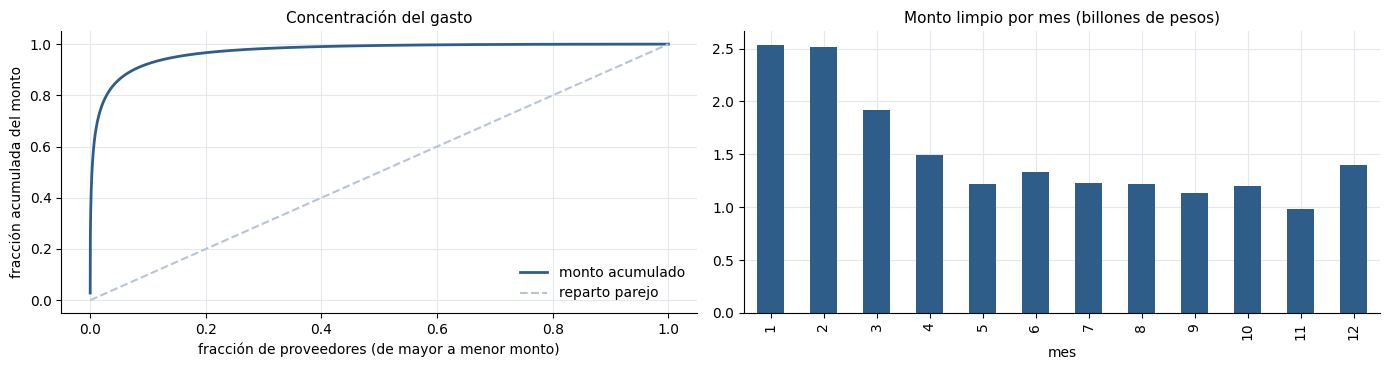

Tipo de proveedor (según rango de RUT):


,proveedores,ordenes,% proveedores,% ordenes,% monto_clp
g,,,,,
RUT desconocido,243,963,0.3,0.1,0.5
persona jurídica,48037,1613514,63.5,87.1,94.8
persona natural (RUT < 50 M),27320,238913,36.1,12.9,4.8


Evolución mensual:


,monto_limpio,ordenes,proveedores,organismos
mes,,,,
1,"2,536,537,075,110",139260,21645,1052
2,"2,515,299,309,278",126004,21685,1074
3,"1,917,705,720,204",148791,23728,1099
4,"1,490,178,638,184",161575,25157,1108
5,"1,218,192,584,577",156576,24918,1109
6,"1,332,192,184,596",155085,24878,1103
7,"1,229,523,992,043",163893,25396,1103
8,"1,220,028,358,423",159322,26198,1112
9,"1,138,366,516,950",149825,25482,1107


Guardado: /content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile/salida_v2/control_metricas_proveedor.csv


In [ ]:
# Celda 13: rankings de control (los mismos que se harán en Pig)

# Se carga la etapa de órdenes limpias y se toman las órdenes que se usan en los rankings
df = cargar_etapa("ordenes_limpias")
u = df[df.usar == 1].copy()
# Se obtienen como texto el proveedor y el organismo, para agrupar sin problemas de tipo "category"
u["pid"] = u.proveedor_id.astype(str)
u["oid"] = u.cod_organismo.astype(str)

# Se calculan las tres métricas por proveedor: monto limpio, órdenes (una fila por orden) y organismos distintos
metricas = (u.groupby("pid")
             .agg(monto_clp=("monto_clp_limpio", "sum"), n_ordenes=("codigo", "size"),
                  n_organismos=("oid", "nunique"), es_persona_natural=("es_persona_natural", "first")))
metricas["nombre"] = u.drop_duplicates("pid").set_index("pid").nombre_proveedor.astype(str)
metricas["monto_MM"] = (metricas.monto_clp / 1e6).round(0)
metricas.index.name = "proveedor_id"
mostrar = ["nombre", "monto_MM", "n_ordenes", "n_organismos", "es_persona_natural"]

print(f"{len(metricas):,} proveedores con órdenes usadas\n")
print("TOP 10 por monto total (millones de pesos)")
display(metricas.sort_values("monto_clp", ascending=False)[mostrar].head(10))
print("TOP 10 por número de órdenes")
display(metricas.sort_values("n_ordenes", ascending=False)[mostrar].head(10))
print("TOP 10 por organismos distintos")
display(metricas.sort_values(["n_organismos", "n_ordenes"], ascending=False)[mostrar].head(10))

# ------------------------- CONCENTRACIÓN DEL GASTO -------------------------

# Se ordenan los proveedores de mayor a menor monto y se calcula el porcentaje acumulado del monto total
m = metricas.monto_clp.sort_values(ascending=False).reset_index(drop=True)
cum = m.cumsum() / m.sum()
tabla = pd.DataFrame({"proveedores": sorted({1, 10, 100, 1000, int(len(m) * 0.01)})})
tabla["% de los proveedores"] = (100 * tabla.proveedores / len(m)).round(3)
tabla["% del monto"] = [round(100 * cum.iloc[k - 1], 1) for k in tabla.proveedores]
print("Concentración del gasto:")
display(tabla)

# Se dibuja la curva de concentración y el monto limpio por mes
mes = u.groupby("mes").agg(monto_limpio=("monto_clp_limpio", "sum"), ordenes=("codigo", "size"),
                           proveedores=("pid", "nunique"), organismos=("oid", "nunique"))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(1, len(cum) + 1) / len(cum)
ax[0].plot(x, cum.values, color=AZUL, lw=2, label="monto acumulado")
ax[0].plot([0, 1], [0, 1], color=GRIS, ls="--", label="reparto parejo")
ax[0].set_xlabel("fracción de proveedores (de mayor a menor monto)")
ax[0].set_ylabel("fracción acumulada del monto")
ax[0].set_title("Concentración del gasto")
ax[0].legend(frameon=False)
(mes.monto_limpio / 1e12).plot.bar(ax=ax[1], color=AZUL)
ax[1].set_title("Monto limpio por mes (billones de pesos)")
ax[1].set_xlabel("mes")
plt.tight_layout()
plt.show()

# Se resume el tipo de proveedor según el rango de RUT (persona natural o jurídica)
pn = metricas.assign(g=metricas.es_persona_natural.map({"1": "persona natural (RUT < 50 M)", "0": "persona jurídica"}).fillna("RUT desconocido"))
t = pn.groupby("g").agg(proveedores=("nombre", "size"), ordenes=("n_ordenes", "sum"), monto_clp=("monto_clp", "sum"))
for c in ("proveedores", "ordenes", "monto_clp"):
    t[f"% {c}"] = (100 * t[c] / t[c].sum()).round(1)
print("Tipo de proveedor (según rango de RUT):")
display(t.drop(columns="monto_clp"))

# Se muestra la evolución mensual (para comparar con Pig) y se guardan los resultados de control
print("Evolución mensual:")
display(mes.assign(monto_limpio=mes.monto_limpio.map("{:,.0f}".format)))
metricas.to_csv(ruta("control_metricas_proveedor.csv"))
mes.to_csv(ruta("control_evolucion_mensual.csv"))
print("Guardado:", ruta("control_metricas_proveedor.csv"))

## 14. PageRank de control
**Celda 14:** calcula PageRank sobre el grafo organismo → proveedor **leyendo los mismos archivos que se llevan al clúster** (`aristas_ponderadas.tsv` y `nodos.tsv`), con el esquema del Lab 8: factor de amortiguación 0,85 y nodos sin salida repartiendo su masa de forma uniforme. Cuatro variantes:

* **A, dirigido** (organismo → proveedor), sin pesos: lo que se corre en Giraph con `aristas.tsv`.
* **B, bidireccional**, sin pesos (`aristas_bidireccional.tsv`).
* **C, bidireccional, ponderado por monto**.
* **D, bidireccional, ponderado por número de órdenes**.

**Por qué importa la dirección.** En A los organismos no reciben enlaces, así que todos tienen el mismo PageRank y el de un proveedor es la suma de la fracción del gasto de cada organismo que le llega. En B, C y D la importancia circula de ida y vuelta: un proveedor sube más si abastece a organismos que a su vez tienen muchos proveedores.

In [ ]:
# Celda 14: PageRank de control sobre el grafo organismo -> proveedor

# Se exige que existan los archivos exportados y las métricas de la celda 13
exigir("aristas_ponderadas.tsv", "nodos.tsv", "control_metricas_proveedor.csv")

# Se leen las aristas (origen, destino, número de órdenes, monto limpio) y los nombres de los nodos
ar = pd.read_csv(ruta("aristas_ponderadas.tsv"), sep="\t", header=None, dtype={0: str, 1: str},
                 names=["origen", "destino", "n_ordenes", "monto_clp"])
print(f"Aristas: {len(ar):,}")

# Se define el PageRank por iteración de potencia; los nodos sin aristas de salida reparten su masa uniformemente
def pagerank(src, dst, w, n, d=0.85, iters=60):
    salida = np.bincount(src, weights=w, minlength=n)
    sin_salida = salida == 0
    r = np.full(n, 1.0 / n)
    for _ in range(iters):
        por_peso = np.divide(r, salida, out=np.zeros(n), where=~sin_salida)
        nuevo = np.bincount(dst, weights=w * por_peso[src], minlength=n)
        r = (1 - d) / n + d * (nuevo + r[sin_salida].sum() / n)
    return r

# Se asigna un número a cada nodo (organismo o proveedor)
nodos_idx, etiquetas = pd.factorize(pd.concat([ar.origen, ar.destino]))
s, t_ = nodos_idx[:len(ar)], nodos_idx[len(ar):]
n = len(etiquetas)
uno = np.ones(len(ar))
peso_monto = np.maximum(ar.monto_clp.fillna(0).values, 1.0)
peso_ordenes = ar.n_ordenes.values.astype(float)

# Se calculan las cuatro variantes (las bidireccionales duplican cada arista en sentido contrario)
bi_s, bi_t = np.r_[s, t_], np.r_[t_, s]
variantes = {
    "A_dirigido": pagerank(s, t_, uno, n),
    "B_bidireccional": pagerank(bi_s, bi_t, np.r_[uno, uno], n),
    "C_bidir_monto": pagerank(bi_s, bi_t, np.r_[peso_monto, peso_monto], n),
    "D_bidir_ordenes": pagerank(bi_s, bi_t, np.r_[peso_ordenes, peso_ordenes], n),
}
print({k: round(float(v.sum()), 6) for k, v in variantes.items()}, "(cada una debe sumar 1)")

# Se separan los proveedores y se quita el prefijo "PROV_" para poder unirlos con las métricas
pr = pd.DataFrame(variantes, index=etiquetas)
pr = pr[pr.index.str.startswith("PROV_")]
pr.index = pr.index.str[5:]
pr.index.name = "proveedor_id"

# Se unen con las métricas de la celda 13 y se calcula la correlación de Spearman entre medidas
metricas = pd.read_csv(ruta("control_metricas_proveedor.csv"), dtype={"proveedor_id": str}, keep_default_na=False).set_index("proveedor_id")
prov = metricas.join(pr, how="inner")
print(f"Proveedores con PageRank: {len(prov):,}")
print("\nCorrelación de Spearman entre medidas (1 = mismo orden):")
display(prov[["monto_clp", "n_ordenes", "n_organismos"] + list(variantes)].corr(method="spearman").round(2))

# Se muestran los 10 proveedores con mayor PageRank en las variantes A y B
for v in ("A_dirigido", "B_bidireccional"):
    print(f"TOP 10 por PageRank, variante {v}")
    display(prov.sort_values(v, ascending=False)[["nombre", "monto_MM", "n_ordenes", "n_organismos", v]].head(10))

# Se guarda el resultado de control
prov[list(variantes)].to_csv(ruta("control_pagerank.csv"))
print("Guardado:", ruta("control_pagerank.csv"))

Aristas: 476,703
{'A_dirigido': 1.0, 'B_bidireccional': 1.0, 'C_bidir_monto': 1.0, 'D_bidir_ordenes': 1.0} (cada una debe sumar 1)
Proveedores con PageRank: 75,600

Correlación de Spearman entre medidas (1 = mismo orden):


,monto_clp,n_ordenes,n_organismos,A_dirigido,B_bidireccional,C_bidir_monto,D_bidir_ordenes
monto_clp,1.00,0.67,0.52,0.40,0.45,0.96,0.64
n_ordenes,0.67,1.00,0.72,0.54,0.65,0.65,0.95
n_organismos,0.52,0.72,1.00,0.76,0.88,0.51,0.71
A_dirigido,0.40,0.54,0.76,1.00,0.65,0.45,0.59
B_bidireccional,0.45,0.65,0.88,0.65,1.00,0.48,0.71
C_bidir_monto,0.96,0.65,0.51,0.45,0.48,1.00,0.68
D_bidir_ordenes,0.64,0.95,0.71,0.59,0.71,0.68,1.00


TOP 10 por PageRank, variante A_dirigido


,nombre,monto_MM,n_ordenes,n_organismos,A_dirigido
proveedor_id,,,,,
71217,SKY AIRLINE S A,4891.0,16965,460,0.000054
26741,COPEC S.A.,116146.0,11018,830,0.000052
25638,LATAM AIRLINES GROUP S.A.,17317.0,49937,543,0.000052
49120,PROVEEDORES INTEGRALES PRISA S A,19739.0,4757,649,0.000045
27247,GASCO GLP S A,38035.0,8777,699,0.000044
1635531,DELTA GENERACION SPA,2939.0,3482,558,0.000041
26796,ABASTIBLE S.A.,12853.0,6116,401,0.000035
1823111,SOCOEX CHILE SPA,1143.0,2005,601,0.000035
27693,EDENRED CHILE SOCIEDAD ANONIMA,507605.0,5284,463,0.000034


TOP 10 por PageRank, variante B_bidireccional


,nombre,monto_MM,n_ordenes,n_organismos,B_bidireccional
proveedor_id,,,,,
26741,COPEC S.A.,116146.0,11018,830,0.000675
27247,GASCO GLP S A,38035.0,8777,699,0.000571
49120,PROVEEDORES INTEGRALES PRISA S A,19739.0,4757,649,0.000521
1823111,SOCOEX CHILE SPA,1143.0,2005,601,0.000481
1773777,SCM PHARMA SPA,8086.0,6464,597,0.000468
25638,LATAM AIRLINES GROUP S.A.,17317.0,49937,543,0.000464
1635531,DELTA GENERACION SPA,2939.0,3482,558,0.000445
1766003,LEFI SPA,2718.0,1744,539,0.000437
27467,DIMERC S A,17180.0,3761,544,0.000437


Guardado: /content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile/salida_v2/control_pagerank.csv


**Qué se espera ver:** la variante C (ponderada por monto) queda casi igual al ranking por monto (correlación cercana a 0,96), así que no aporta información nueva sobre los perfiles. Las variantes A y B se distinguen del monto (correlación de 0,4 a 0,5) y son las útiles para compararlo con el PageRank. En el informe hay que justificar qué variante se usa.

## 15. Los dos perfiles del profe
**Celda 15:** compara el **percentil por monto** con el **percentil de PageRank** de cada proveedor.

* **Perfil 1: alto monto y bajo PageRank** (top 1 % por monto, mitad inferior de PageRank). Hipótesis: proveedores con uno o pocos contratos muy grandes.
* **Perfil 2: bajo monto y alto PageRank** (mitad inferior por monto, top 1 % de PageRank). Hipótesis: proveedores que abastecen a muchos organismos, aunque con montos modestos.

Primero se cuentan los proveedores de cada perfil con distintas variantes y umbrales, para elegir con criterio, y después se describen los perfiles de la variante elegida.

Proveedores en cada perfil, por variante y umbral:


,variante,umbral_alto,perfil_1,perfil_2
0,A_dirigido,top 1 %,142,10
1,A_dirigido,top 5 %,656,108
2,B_bidireccional,top 1 %,91,0
3,B_bidireccional,top 5 %,558,15
4,C_bidir_monto,top 1 %,0,0
5,C_bidir_monto,top 5 %,0,0
6,D_bidir_ordenes,top 1 %,84,0
7,D_bidir_ordenes,top 5 %,372,6


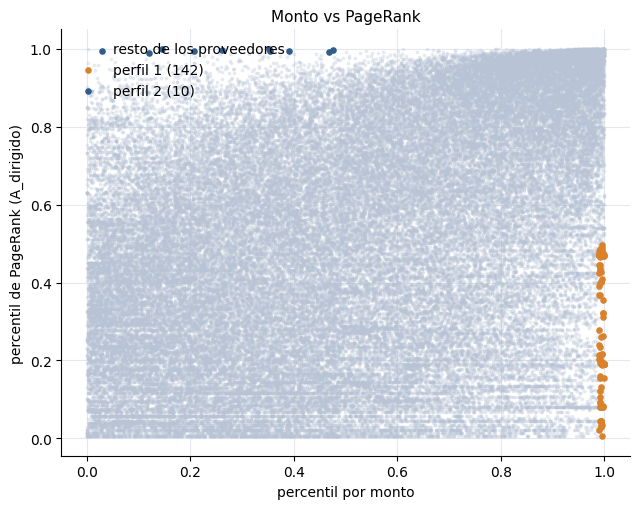

Mediana de todos los proveedores: 3 órdenes, 1 organismos

Perfil 1: 142 proveedores | mediana de órdenes = 2, de organismos = 1


,nombre,monto_MM,n_ordenes,n_organismos,pct_monto,pct_A_dirigido,rubro_principal
proveedor_id,,,,,,,
97685,Salud y Vida S.A.,480842.0,3,1,1.000,0.192,"Organizaciones y consultorías políticas,"
83487,sosersa,456447.0,6,1,1.000,0.192,"Organizaciones y consultorías políticas,"
27324,SERVICIOS ALIMENTICIOS HENDAYA SAC,211809.0,3,1,1.000,0.192,"Organizaciones y consultorías políticas,"
79625,teleton,59829.0,1,1,1.000,0.471,"Educación, formación, entrenamiento y ca"
1654303,Francisco,55396.0,3,1,1.000,0.471,"Salud, servicios sanitarios y alimentaci"
1442456,Fernando,48619.0,3,1,1.000,0.192,"Organizaciones y consultorías políticas,"
1083802,Nutriplus Alimentacion y Tecnologia S.A.,45040.0,4,1,1.000,0.192,"Organizaciones y consultorías políticas,"
136347,Gastronomia Integral Ltda,38154.0,2,1,0.999,0.192,"Organizaciones y consultorías políticas,"
1765862,CHINA RAILWAY CONSTRUCTION CORPORATION (I...,30611.0,3,1,0.999,0.469,Servicios de construcción y mantenimient



Perfil 2: 10 proveedores | mediana de órdenes = 4, de organismos = 2


,nombre,monto_MM,n_ordenes,n_organismos,pct_monto,pct_A_dirigido,rubro_principal
proveedor_id,,,,,,,
2025042,PLAYOFF CHILE SPA,3.0,3,2,0.352,0.999,Servicios de cuidado personal y doméstic
138142,JUAN JOSÉ UGALDE NÚÑEZ,1.0,4,2,0.145,0.999,"Servicios de Viajes, alimentación, aloja"
1492610,MACROFOLIO ESTUDIO CREATIVO MICHAEL RICHA...,7.0,8,7,0.476,0.998,"Servicios editoriales, de diseño, public"
1177372,inversiones pukara ltda,2.0,2,2,0.260,0.996,"Servicios de Viajes, alimentación, aloja"
1443065,Iván Lázaro,1.0,6,5,0.207,0.994,"Instrumentos musicales, juegos, juguetes"
2053117,COMERCIALIZADORA DISPENSA CHILE LIMITADA,3.0,6,6,0.353,0.994,Artículos para plantas y animales
2021859,WECHE SPA,4.0,2,2,0.391,0.993,"Servicios editoriales, de diseño, public"
1754286,YOHANA ALEJANDRA CASTILLO SALINAS,0.0,2,1,0.028,0.993,"Alimentos, bebidas y tabaco"
1875006,SAN MARTÍN Y ARGOMEDO LIMITADA,7.0,14,12,0.468,0.992,"Servicios de Viajes, alimentación, aloja"


Guardado: /content/drive/MyDrive/Proyecto Grupo 13 Ranking de Proveedores del Estado de Chile/salida_v2/control_perfiles.csv


In [ ]:
# Celda 15: los dos perfiles (monto vs PageRank)

# Se exige que existan los resultados de las celdas 13 y 14
exigir("control_metricas_proveedor.csv", "control_pagerank.csv")

# Se define la variante de PageRank con la que se describen los perfiles (se puede cambiar por "B_bidireccional", etc.)
VARIANTE = "A_dirigido"

# Se leen las métricas y el PageRank de control, y se unen por proveedor
metricas = pd.read_csv(ruta("control_metricas_proveedor.csv"), dtype={"proveedor_id": str}, keep_default_na=False).set_index("proveedor_id")
pr = pd.read_csv(ruta("control_pagerank.csv"), dtype={"proveedor_id": str}).set_index("proveedor_id")
prov = metricas.join(pr, how="inner")

# Se calcula el percentil de cada proveedor por monto y por cada variante de PageRank (1.0 = el más alto)
prov["pct_monto"] = prov.monto_clp.rank(pct=True)
for v in pr.columns:
    prov["pct_" + v] = prov[v].rank(pct=True)

# Se cuenta cuántos proveedores caen en cada perfil según la variante y el umbral
filas = []
for v in pr.columns:
    for alto in (0.99, 0.95):
        p1 = int(((prov.pct_monto >= alto) & (prov["pct_" + v] <= PERFIL_BAJO)).sum())
        p2 = int(((prov.pct_monto <= PERFIL_BAJO) & (prov["pct_" + v] >= alto)).sum())
        filas.append({"variante": v, "umbral_alto": f"top {round((1 - alto) * 100)} %", "perfil_1": p1, "perfil_2": p2})
print("Proveedores en cada perfil, por variante y umbral:")
display(pd.DataFrame(filas))

# Se asignan los perfiles con la variante elegida y los umbrales de la celda 1
pc = "pct_" + VARIANTE
prov["perfil"] = ""
prov.loc[(prov.pct_monto >= PERFIL_ALTO) & (prov[pc] <= PERFIL_BAJO), "perfil"] = "1: alto monto, bajo PageRank"
prov.loc[(prov.pct_monto <= PERFIL_BAJO) & (prov[pc] >= PERFIL_ALTO), "perfil"] = "2: bajo monto, alto PageRank"

# Se agrega el rubro principal de cada proveedor (el de mayor monto neto), de la tabla proveedor x rubro
rub = cargar_etapa("proveedor_rubro")
rub = rub.sort_values("monto_neto_clp", ascending=False).drop_duplicates("cod_proveedor").set_index("cod_proveedor")["rubro"]
prov["rubro_principal"] = prov.index.map(rub).astype(str).str.slice(0, 40)

# Se dibujan todos los proveedores y se destacan los de cada perfil
fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.scatter(prov.pct_monto, prov[pc], s=3, alpha=.25, color=GRIS, label="resto de los proveedores")
for p, col in (("1", NARANJA), ("2", AZUL)):
    q = prov[prov.perfil.str.startswith(p)]
    ax.scatter(q.pct_monto, q[pc], s=14, color=col, label=f"perfil {p} ({len(q)})")
ax.set_xlabel("percentil por monto")
ax.set_ylabel(f"percentil de PageRank ({VARIANTE})")
ax.set_title("Monto vs PageRank")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# Se describen los perfiles: cuántos son, medianas de órdenes y organismos (frente al total) y los 10 principales
print(f"Mediana de todos los proveedores: {prov.n_ordenes.median():.0f} órdenes, {prov.n_organismos.median():.0f} organismos")
cols = ["nombre", "monto_MM", "n_ordenes", "n_organismos", "pct_monto", pc, "rubro_principal"]
for p in ("1", "2"):
    q = prov[prov.perfil.str.startswith(p)]
    orden = "monto_clp" if p == "1" else VARIANTE
    print(f"\nPerfil {p}: {len(q)} proveedores | mediana de órdenes = {q.n_ordenes.median():.0f}, de organismos = {q.n_organismos.median():.0f}")
    if len(q):
        display(q.sort_values(orden, ascending=False)[cols].head(10).round(3))

# Se guarda el resultado completo (todos los proveedores con percentiles y perfil)
prov.to_csv(ruta("control_perfiles.csv"))
print("Guardado:", ruta("control_perfiles.csv"))

## 16. Siguiente paso: llevar los datos al clúster
Los archivos que se suben son `ordenes_limpias.tsv.bz2`, `ordenes_muestra.tsv`, `aristas.tsv`, `aristas_muestra.tsv` (y, si se usan, `aristas_bidireccional.tsv`, `nodos.tsv` y `proveedor_rubro.tsv`), desde `salida_v2`. Reemplaza `<grupo>` por la carpeta del grupo:

```bash
# desde el computador de cada uno (-P en mayúscula)
scp -P 220 ordenes_limpias.tsv.bz2 ordenes_muestra.tsv aristas*.tsv nodos.tsv proveedor_rubro.tsv uhadoop@cm.dcc.uchile.cl:/data/2026/uhadoop/projects/<grupo>/

# en el clúster
hdfs dfs -mkdir -p /uhadoop2026/projects/<grupo>
hdfs dfs -copyFromLocal ordenes_limpias.tsv.bz2 aristas.tsv aristas_bidireccional.tsv nodos.tsv proveedor_rubro.tsv ordenes_muestra.tsv aristas_muestra.tsv /uhadoop2026/projects/<grupo>/
hdfs dfs -ls -h /uhadoop2026/projects/<grupo>
```

Esquema de **Pig** (el archivo trae cabecera, que se filtra; los campos numéricos vacíos quedan como `null` y `SUM` los ignora):

```pig
ordenes = LOAD '/uhadoop2026/projects/<grupo>/ordenes_limpias.tsv.bz2' USING PigStorage('\t') AS (
    codigo:chararray, mes:int, fecha_envio:chararray, fecha_creacion:chararray, fecha_aceptacion:chararray,
    estado:chararray, estado_proveedor:chararray, tipo:chararray, procedencia:chararray,
    cod_licitacion:chararray, cod_convenio_marco:chararray, moneda:chararray, monto_original:double,
    monto_clp:double, monto_clp_corr:double, monto_corregido:int, monto_clp_limpio:double,
    flag_monto:chararray, n_items:int, cod_organismo:chararray, organismo:chararray, sector:chararray,
    region_comprador:chararray, proveedor_id:chararray, rut_proveedor:chararray, nombre_proveedor:chararray,
    es_persona_natural:chararray, region_proveedor:chararray, actividad_proveedor:chararray, usar:int);
validas = FILTER ordenes BY codigo != 'codigo' AND usar == 1;
```

* **Giraph:** `aristas.tsv` (y `aristas_bidireccional.tsv`) con el mismo formato de entrada del Lab 8. Probar primero con `pr-ex.tsv` y con `aristas_muestra.tsv`.
* **Para comprobar los resultados:** comparar con `control_metricas_proveedor.csv`, `control_evolucion_mensual.csv` y `control_pagerank.csv`.